In [3]:
import os
import random
import shutil
import yaml
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [4]:
SOURCE = r"dataset"
YES = os.path.join(SOURCE, "Yes")
NO = os.path.join(SOURCE, "No")
LABELS = os.path.join(SOURCE, "labels")
OUTPUT = os.path.join(SOURCE, "YOLO_Dataset")

train_img = os.path.join(OUTPUT, "images", "train")
val_img = os.path.join(OUTPUT, "images", "val")

train_lbl = os.path.join(OUTPUT, "labels", "train")
val_lbl = os.path.join(OUTPUT, "labels", "val")

for p in [train_img, val_img, train_lbl, val_lbl]:
    os.makedirs(p, exist_ok=True)
yes_images = [
    f for f in os.listdir(YES) if f.lower().endswith((".jpg", ".png", ".jpeg"))
]
no_images = [f for f in os.listdir(NO) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
all_images = [("yes", x) for x in yes_images] + [("no", x) for x in no_images]
random.shuffle(all_images)
split = int(len(all_images) * 0.8)
train = all_images[:split]
val = all_images[split:]


def copy_dataset(dataset, img_folder, lbl_folder):
    for cls, img in dataset:
        if cls == "yes":
            src = os.path.join(YES, img)
        else:
            src = os.path.join(NO, img)
        shutil.copy(src, os.path.join(img_folder, img))
        txt = os.path.splitext(img)[0] + ".txt"
        if cls == "yes":
            src_label = os.path.join(LABELS, txt)
            if os.path.exists(src_label):
                shutil.copy(src_label, os.path.join(lbl_folder, txt))
            else:
                open(os.path.join(lbl_folder, txt), "w").close()
        else:
            open(os.path.join(lbl_folder, txt), "w").close()


copy_dataset(train, train_img, train_lbl)
copy_dataset(val, val_img, val_lbl)


yaml_data = {
    "path": OUTPUT,
    "train": "images/train",
    "val": "images/val",
    "names": {0: "Tumor"},
}

with open(os.path.join(OUTPUT, "data.yaml"), "w") as f:
    yaml.dump(yaml_data, f, sort_keys=False)

In [ ]:
model = YOLO("yolov8s.pt")
model.train(
    data=r"YOLO_Dataset\data.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    workers=4,
    device="cpu",
    project="BrainTumor",
    name="YOLOv8s",
    patience=5,
)

### Info from model 
model = YOLO(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
print("Model Loaded Successfully")
print("============================")
print("========== Classes ==========")
for id, name in model.names.items():
    print(f"Class ID {id}: {name}")
print("============================")
parameters = sum(p.numel() for p in model.model.parameters())
print(f"Total Parameters: {parameters:,}")
print("============================================")
print("Input Image Size: 640x640")
print("========== Training Configuration ==========")
print("Epochs: 10")
print("Image Size: 640")
print("Batch Size: 16")
print("Device: CPU")
print("Optimizer: YOLO Default")
print("============================================")
print("Model Path:")
print(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
print("Model Size:")
size = os.path.getsize(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt") / (1024 * 1024)
print(f"{size:.2f} MB")

In [5]:
from ultralytics import YOLO

model = YOLO(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
image_path = r"dataset\YES\Y45.JPG"

for conf in [
    0.05,
    0.1,
    0.15,
    0.2,
    0.25,
    0.3,
    0.35,
    0.4,
    0.45,
    0.5,
    0.55,
    0.6,
    0.65,
    0.7,
    0.75,
    0.8,
    0.85,
    0.9,
    0.95,
]:
    results = model.predict(source=image_path, conf=conf, verbose=False)
    boxes = results[0].boxes
    if len(boxes) > 0:
        confidence = float(boxes.conf.max())
        print(f"conf={conf:.2f}  -> Tumor detected | confidence={confidence:.2%}")
    else:
        print(f"conf={conf:.2f}  -> No Tumor")

conf=0.05  -> Tumor detected | confidence=66.51%
conf=0.10  -> Tumor detected | confidence=66.51%
conf=0.15  -> Tumor detected | confidence=66.51%
conf=0.20  -> Tumor detected | confidence=66.51%
conf=0.25  -> Tumor detected | confidence=66.51%
conf=0.30  -> Tumor detected | confidence=66.51%
conf=0.35  -> Tumor detected | confidence=66.51%
conf=0.40  -> Tumor detected | confidence=66.51%
conf=0.45  -> Tumor detected | confidence=66.51%
conf=0.50  -> Tumor detected | confidence=66.51%
conf=0.55  -> Tumor detected | confidence=66.51%
conf=0.60  -> Tumor detected | confidence=66.51%
conf=0.65  -> Tumor detected | confidence=66.51%
conf=0.70  -> No Tumor
conf=0.75  -> No Tumor
conf=0.80  -> No Tumor
conf=0.85  -> No Tumor
conf=0.90  -> No Tumor
conf=0.95  -> No Tumor



image 1/1 e:\Brain Tumor Detection\dataset\YES\Y73.jpg: 640x576 1 Tumor, 155.0ms
Speed: 3.4ms preprocess, 155.0ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 576)
Number of boxes: 1
Box 1 - Confidence: 63.49%


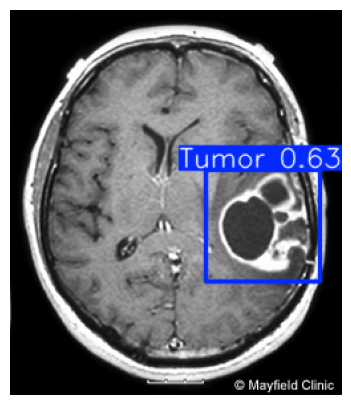

In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
image_path = "dataset/YES/Y73.jpg"
results = model.predict(source=image_path, conf=0.2, save=False, show=False)
result = results[0]
print("Number of boxes:", len(result.boxes))
if len(result.boxes) > 0:
    for i, box in enumerate(result.boxes):
        confidence = float(box.conf[0])
        print(f"Box {i + 1} - Confidence: {confidence * 100:.2f}%")
annotated = result.plot()
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


image 1/1 e:\Brain Tumor Detection\image test\image(2).jpg: 640x576 1 Tumor, 196.3ms
Speed: 4.6ms preprocess, 196.3ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 576)
image(2) -> Tumor: 71.75%


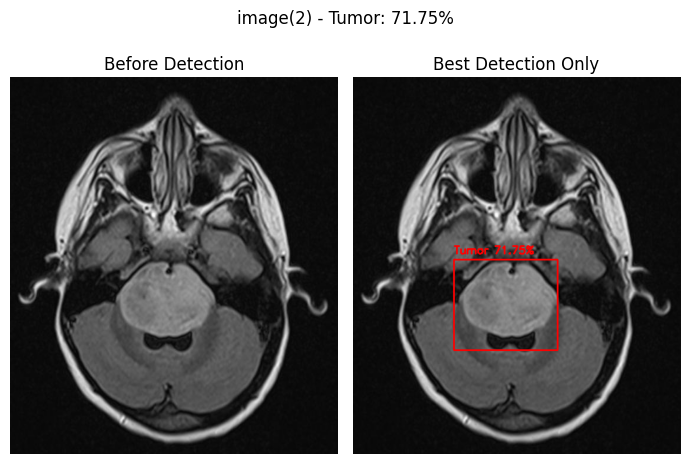


image 1/1 e:\Brain Tumor Detection\image test\image(3).jpg: 640x640 2 Tumors, 229.8ms
Speed: 8.4ms preprocess, 229.8ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 640)
image(3) -> Tumor: 61.91%


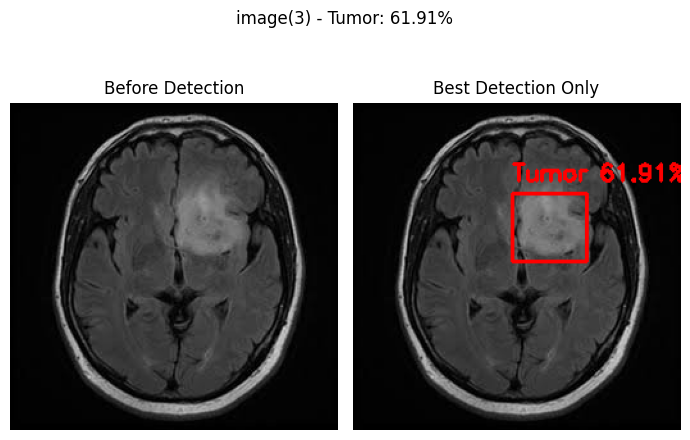


image 1/1 e:\Brain Tumor Detection\image test\image(4).jpg: 544x640 4 Tumors, 244.7ms
Speed: 3.7ms preprocess, 244.7ms inference, 1.8ms postprocess per image at shape (1, 3, 544, 640)
image(4) -> Tumor: 85.82%


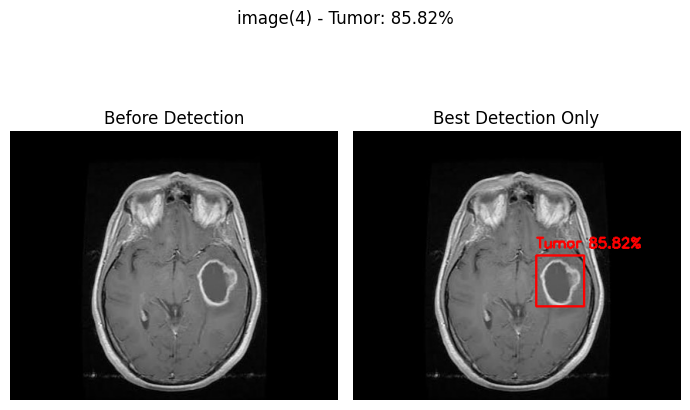


image 1/1 e:\Brain Tumor Detection\image test\image(5).jpg: 640x544 4 Tumors, 223.8ms
Speed: 5.3ms preprocess, 223.8ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 544)
image(5) -> Tumor: 30.87%


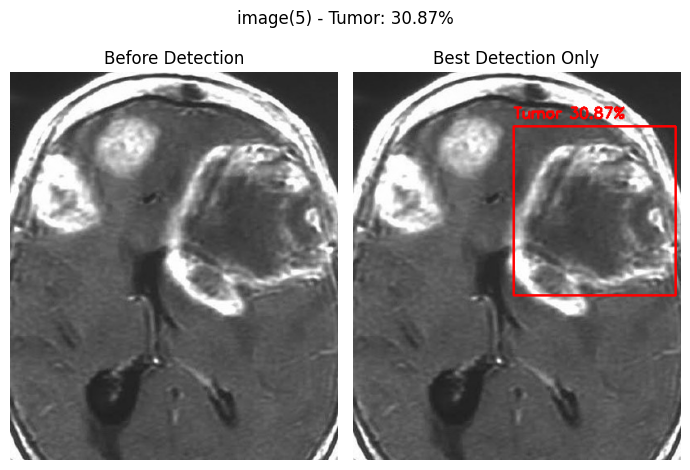


image 1/1 e:\Brain Tumor Detection\image test\image(6).jpg: 640x640 2 Tumors, 212.2ms
Speed: 5.4ms preprocess, 212.2ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
image(6) -> Tumor: 61.91%


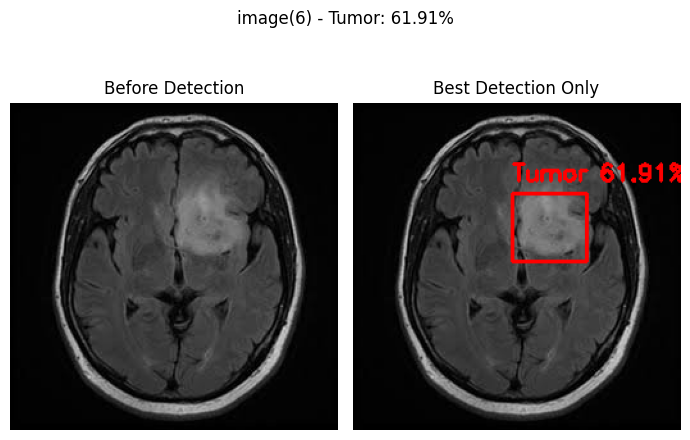


image 1/1 e:\Brain Tumor Detection\image test\image(7).jpg: 608x640 3 Tumors, 192.9ms
Speed: 3.6ms preprocess, 192.9ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 640)
image(7) -> Tumor: 85.01%


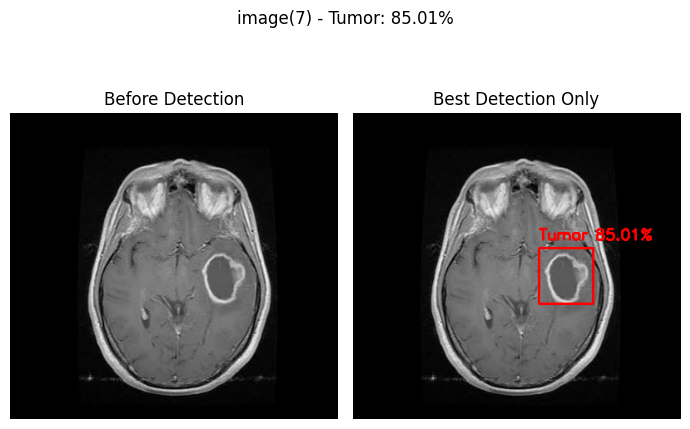


image 1/1 e:\Brain Tumor Detection\image test\image(8).jpg: 640x576 1 Tumor, 146.3ms
Speed: 3.3ms preprocess, 146.3ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 576)
image(8) -> Tumor: 32.56%


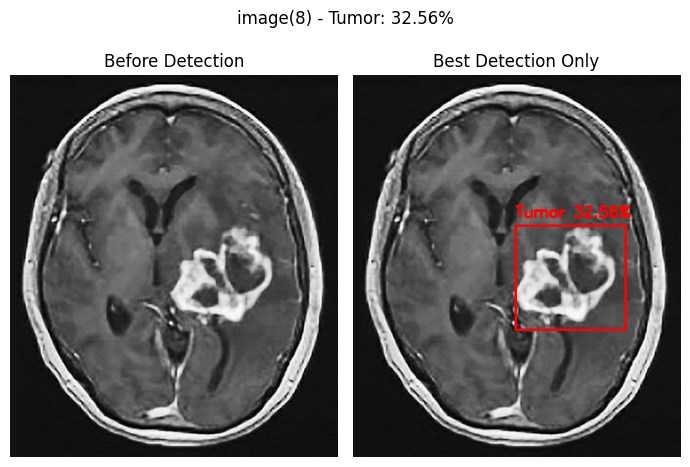


image 1/1 e:\Brain Tumor Detection\image test\image(9).jpg: 640x608 2 Tumors, 181.1ms
Speed: 3.2ms preprocess, 181.1ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 608)
image(9) -> Tumor: 51.51%


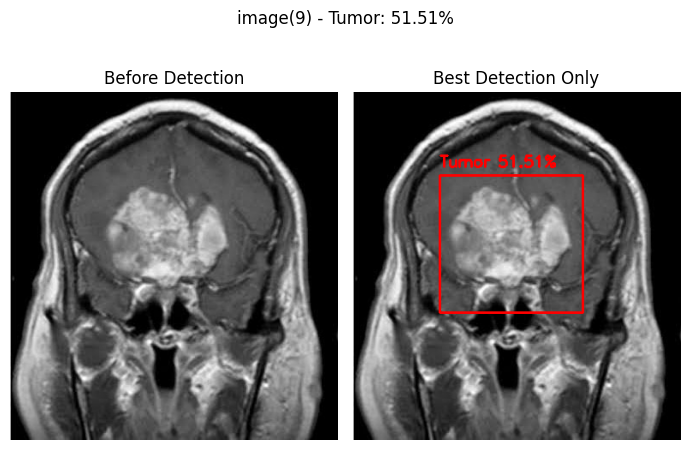


image 1/1 e:\Brain Tumor Detection\image test\image(10).jpg: 640x608 2 Tumors, 156.0ms
Speed: 5.0ms preprocess, 156.0ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 608)
image(10) -> Tumor: 21.19%


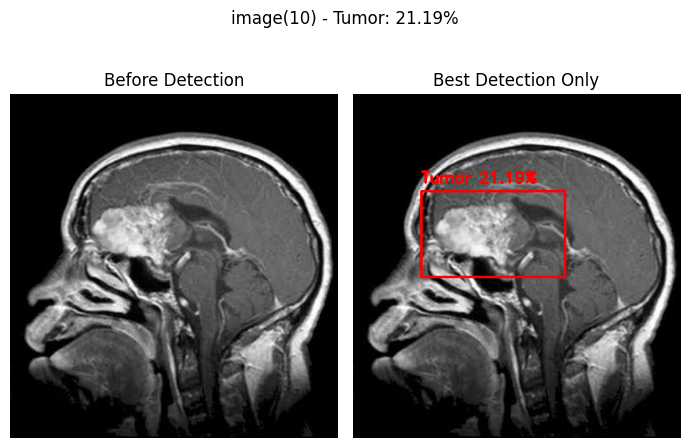


image 1/1 e:\Brain Tumor Detection\image test\image(11).jpg: 640x608 1 Tumor, 150.1ms
Speed: 3.7ms preprocess, 150.1ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 608)
image(11) -> Tumor: 68.99%


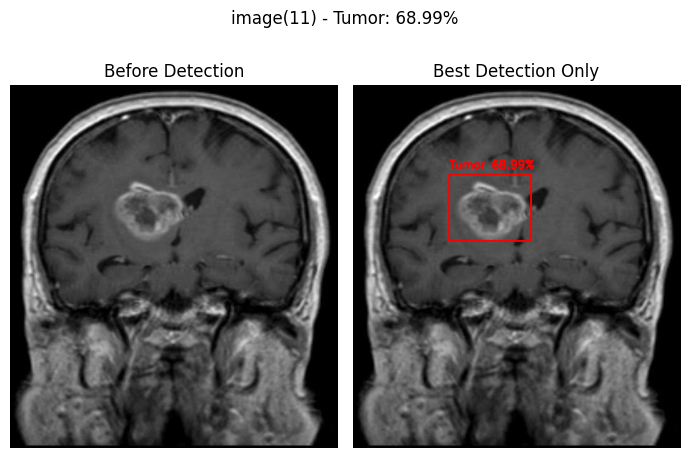


image 1/1 e:\Brain Tumor Detection\image test\image(12).jpg: 640x608 1 Tumor, 147.8ms
Speed: 4.0ms preprocess, 147.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 608)
image(12) -> Tumor: 68.99%


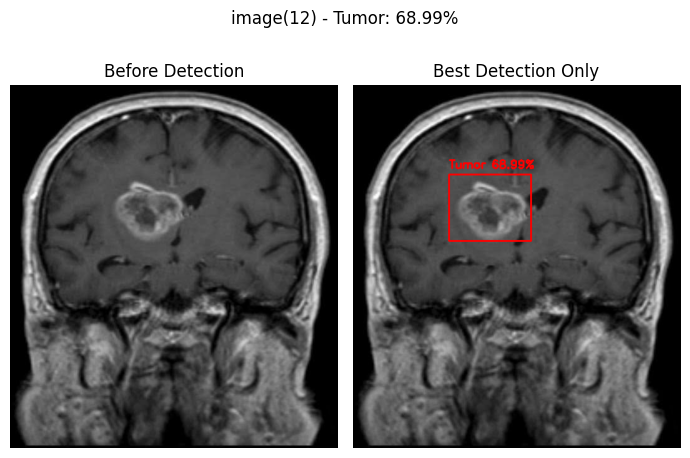


image 1/1 e:\Brain Tumor Detection\image test\image(13).jpg: 640x608 2 Tumors, 165.3ms
Speed: 3.1ms preprocess, 165.3ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 608)
image(13) -> Tumor: 59.78%


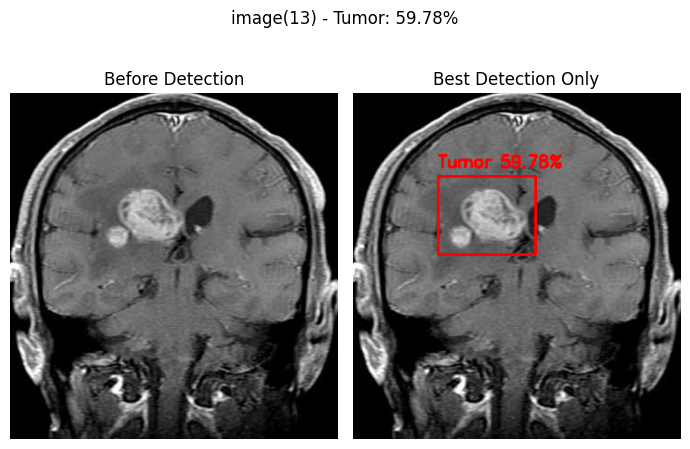


image 1/1 e:\Brain Tumor Detection\image test\image(14).jpg: 640x608 3 Tumors, 171.4ms
Speed: 18.9ms preprocess, 171.4ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 608)
image(14) -> Tumor: 60.65%


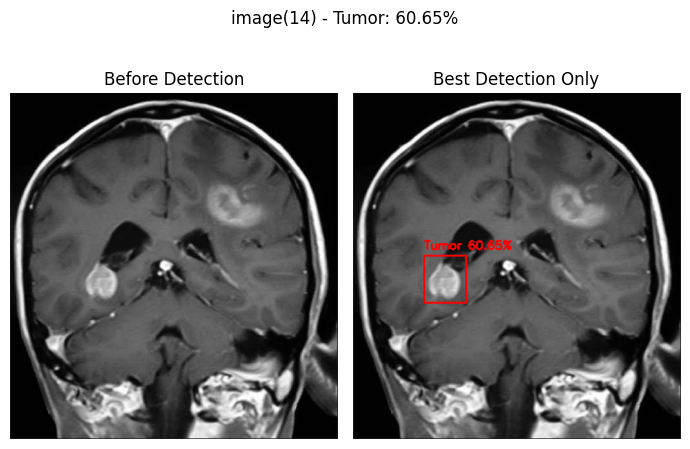


image 1/1 e:\Brain Tumor Detection\image test\image(15).jpg: 640x608 (no detections), 160.5ms
Speed: 3.8ms preprocess, 160.5ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 608)
image(15) -> No Tumor Detected


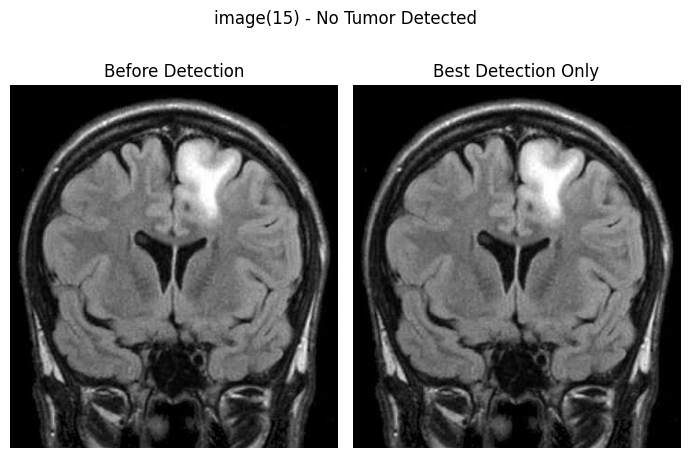


image 1/1 e:\Brain Tumor Detection\image test\image(16).jpg: 640x640 (no detections), 172.4ms
Speed: 4.1ms preprocess, 172.4ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
image(16) -> No Tumor Detected


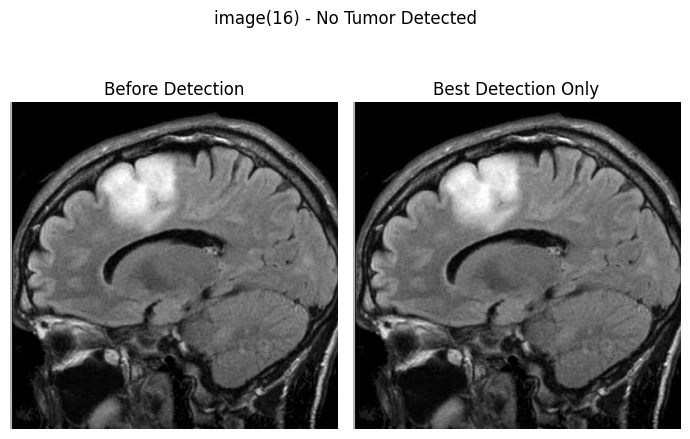


image 1/1 e:\Brain Tumor Detection\image test\image(17).jpg: 640x640 1 Tumor, 166.6ms
Speed: 4.3ms preprocess, 166.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
image(17) -> Tumor: 73.71%


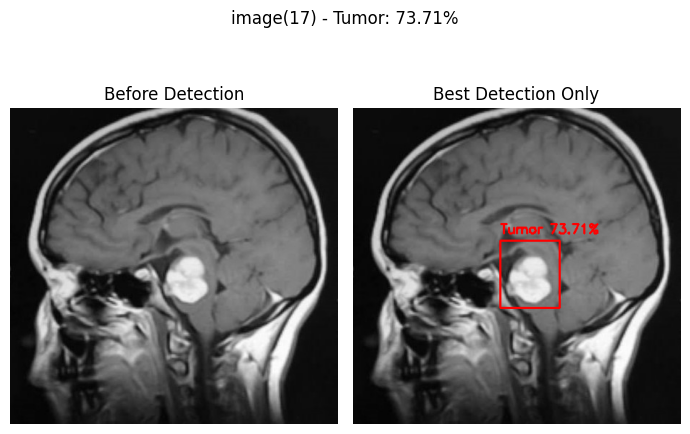


image 1/1 e:\Brain Tumor Detection\image test\image(18).jpg: 640x544 3 Tumors, 149.3ms
Speed: 3.4ms preprocess, 149.3ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 544)
image(18) -> Tumor: 49.42%


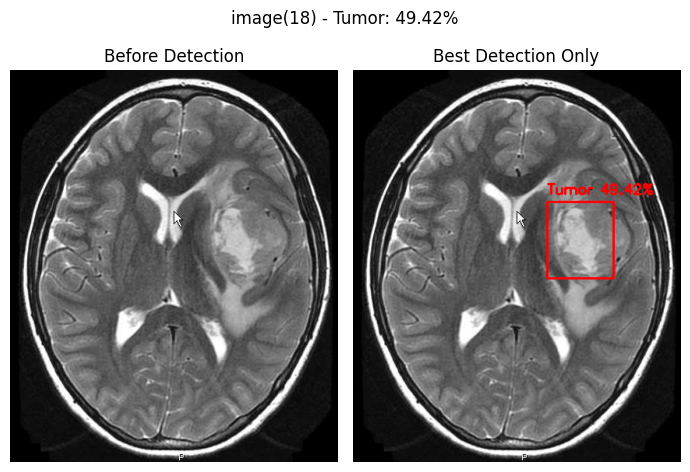


image 1/1 e:\Brain Tumor Detection\image test\image(19).jpg: 640x640 2 Tumors, 216.9ms
Speed: 18.1ms preprocess, 216.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
image(19) -> Tumor: 74.88%


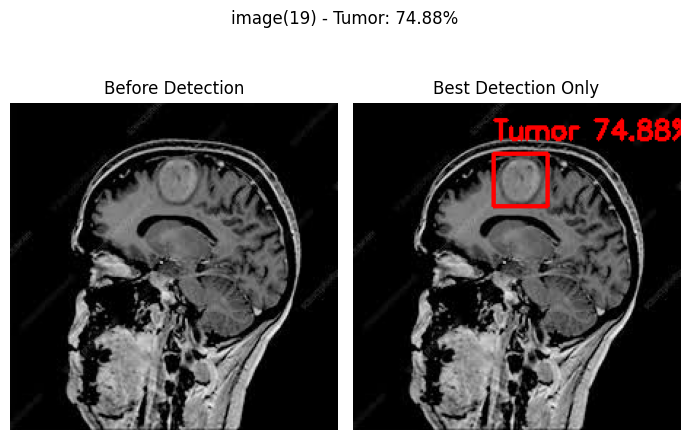


image 1/1 e:\Brain Tumor Detection\image test\image(20).jpg: 640x608 1 Tumor, 194.1ms
Speed: 3.6ms preprocess, 194.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 608)
image(20) -> Tumor: 43.83%


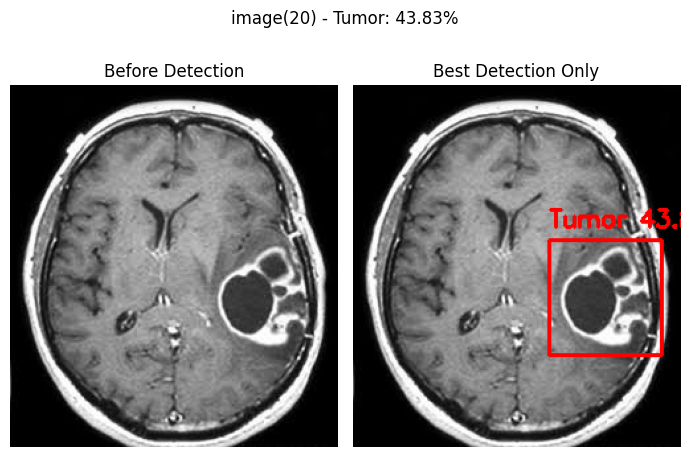


image 1/1 e:\Brain Tumor Detection\image test\image(21).jpg: 640x640 1 Tumor, 189.3ms
Speed: 5.0ms preprocess, 189.3ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
image(21) -> Tumor: 60.45%


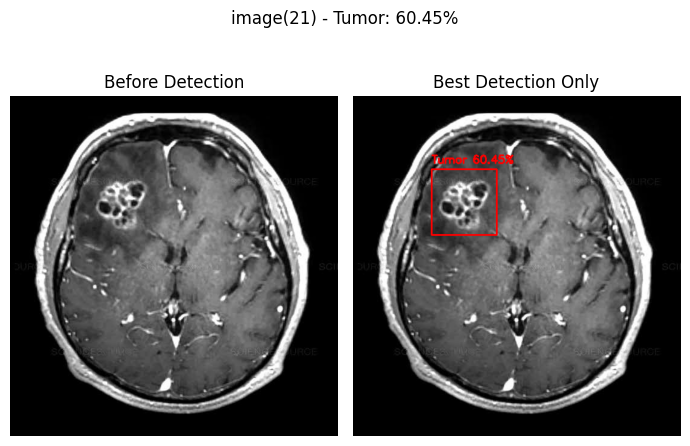


image 1/1 e:\Brain Tumor Detection\image test\image(22).jpg: 640x512 4 Tumors, 203.1ms
Speed: 5.2ms preprocess, 203.1ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 512)
image(22) -> Tumor: 72.77%


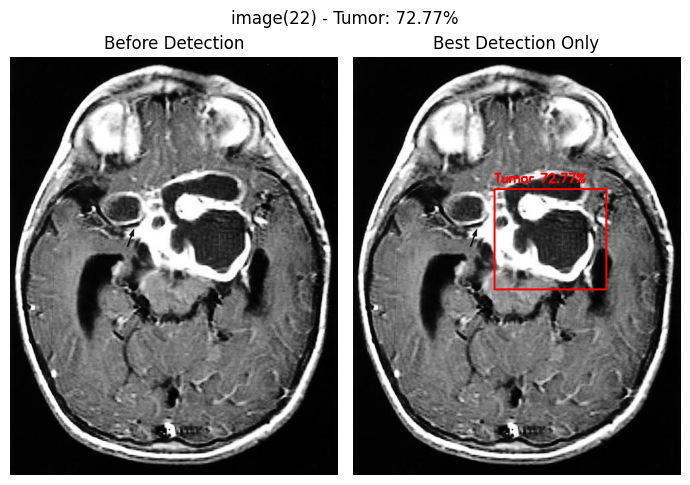


image 1/1 e:\Brain Tumor Detection\image test\image(23).jpg: 640x576 1 Tumor, 146.6ms
Speed: 3.9ms preprocess, 146.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 576)
image(23) -> Tumor: 35.08%


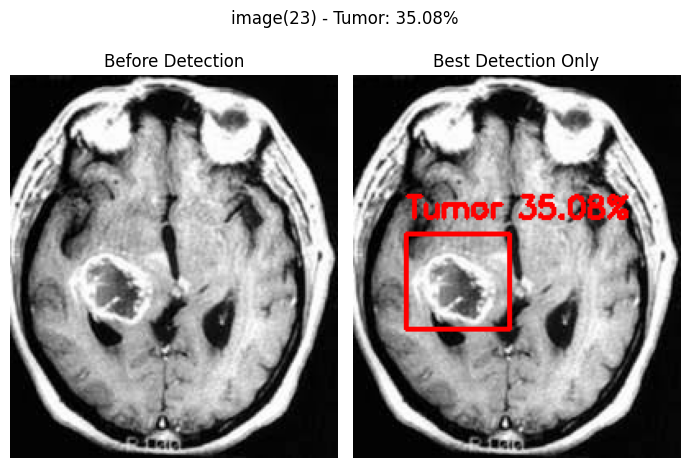


image 1/1 e:\Brain Tumor Detection\image test\image(24).jpg: 640x576 1 Tumor, 196.7ms
Speed: 4.1ms preprocess, 196.7ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 576)
image(24) -> Tumor: 19.97%


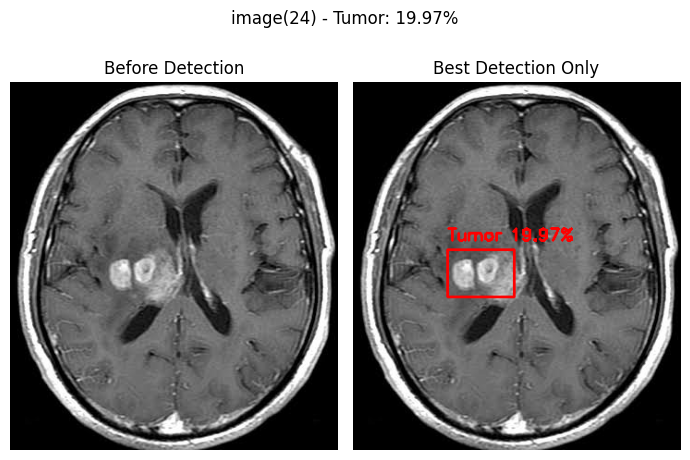


image 1/1 e:\Brain Tumor Detection\image test\image(25).jpg: 576x640 (no detections), 191.4ms
Speed: 4.9ms preprocess, 191.4ms inference, 0.8ms postprocess per image at shape (1, 3, 576, 640)
image(25) -> No Tumor Detected


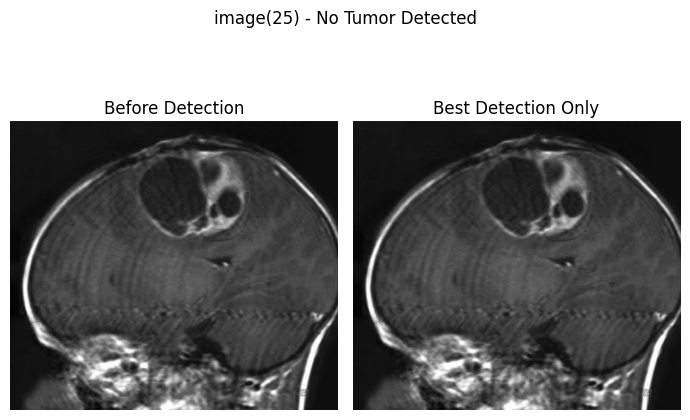


image 1/1 e:\Brain Tumor Detection\image test\image(26).jpg: 448x640 2 Tumors, 164.8ms
Speed: 2.5ms preprocess, 164.8ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)
image(26) -> Tumor: 78.75%


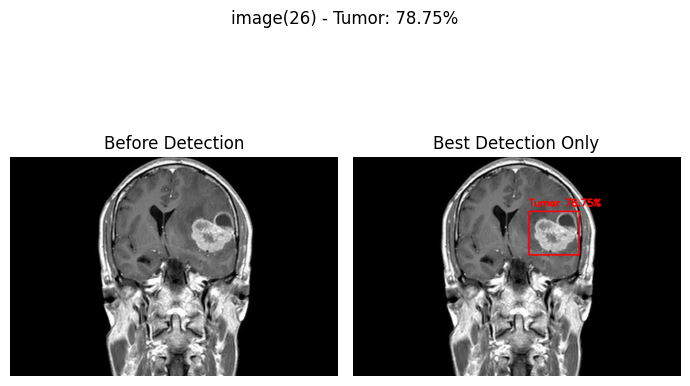


image 1/1 e:\Brain Tumor Detection\image test\image(27).jpg: 640x640 3 Tumors, 198.4ms
Speed: 6.6ms preprocess, 198.4ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
image(27) -> Tumor: 50.69%


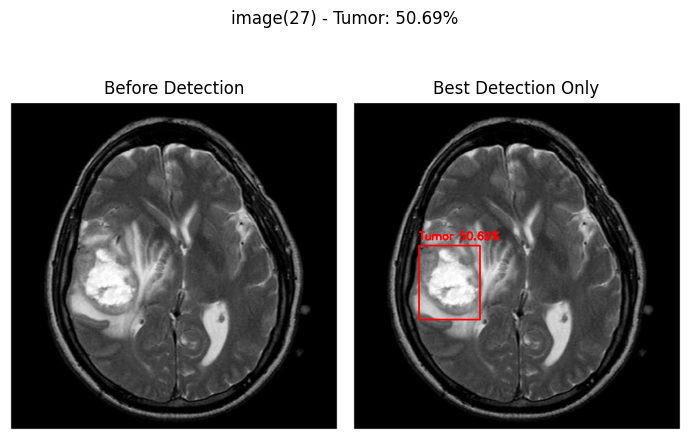


image 1/1 e:\Brain Tumor Detection\image test\image(28).jpg: 640x576 1 Tumor, 301.8ms
Speed: 4.7ms preprocess, 301.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 576)
image(28) -> Tumor: 77.88%


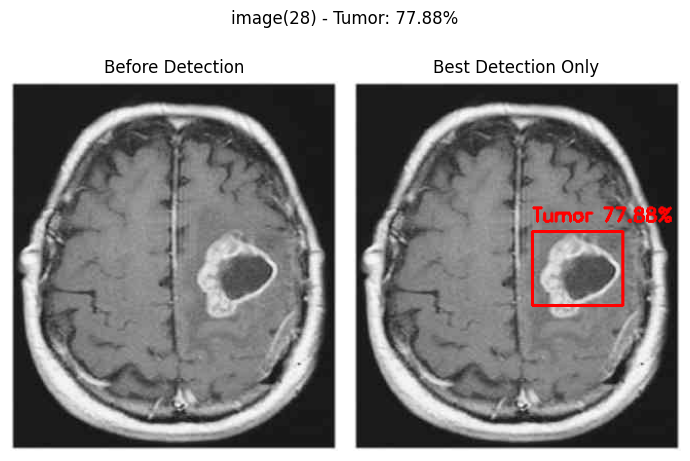


image 1/1 e:\Brain Tumor Detection\image test\image(29).jpg: 640x576 1 Tumor, 181.7ms
Speed: 72.1ms preprocess, 181.7ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 576)
image(29) -> Tumor: 77.88%


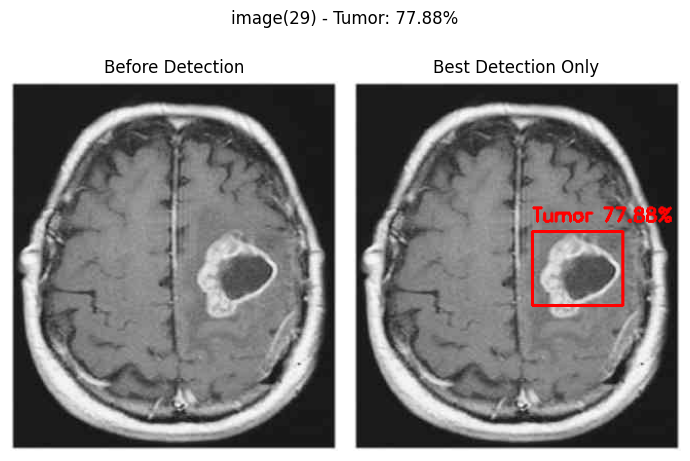


image 1/1 e:\Brain Tumor Detection\image test\image(30).jpg: 640x544 2 Tumors, 177.3ms
Speed: 4.1ms preprocess, 177.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 544)
image(30) -> Tumor: 25.99%


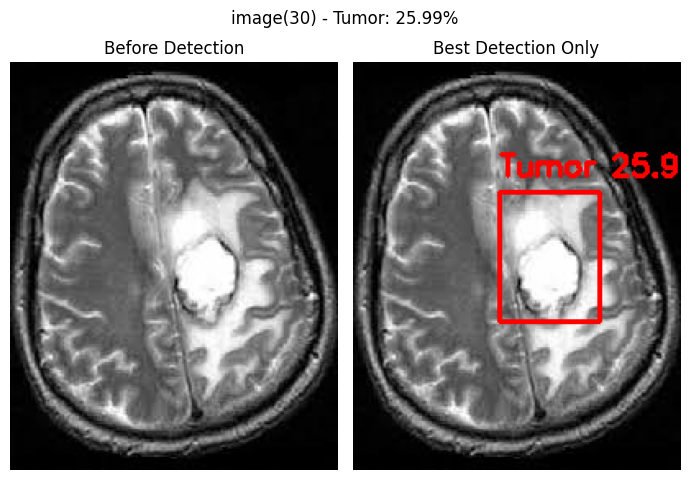


image 1/1 e:\Brain Tumor Detection\image test\image(31).jpg: 640x640 2 Tumors, 190.9ms
Speed: 4.3ms preprocess, 190.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
image(31) -> Tumor: 51.80%


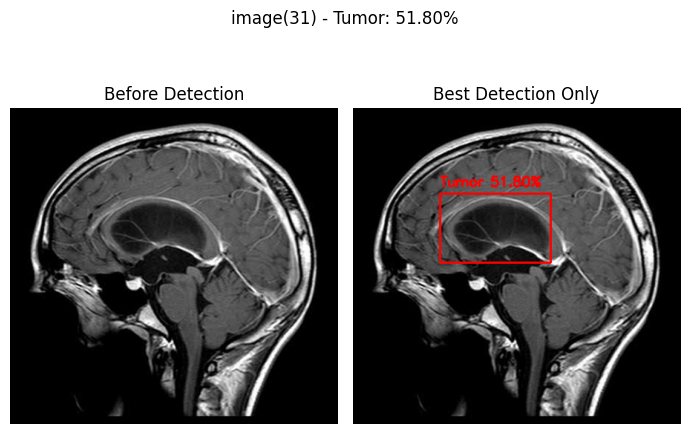


image 1/1 e:\Brain Tumor Detection\image test\image(32).jpg: 640x640 3 Tumors, 183.1ms
Speed: 4.1ms preprocess, 183.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
image(32) -> Tumor: 69.35%


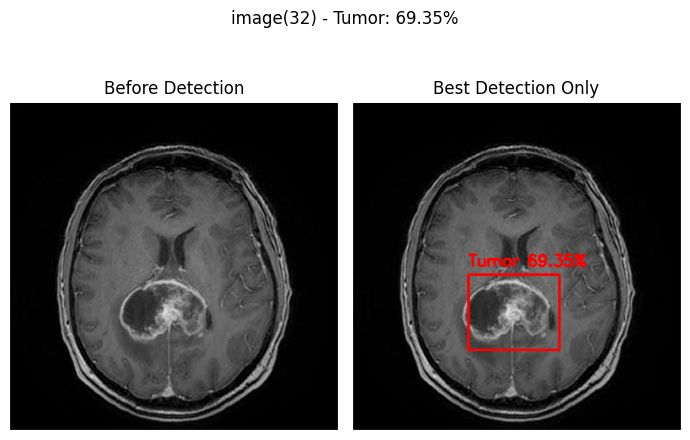


image 1/1 e:\Brain Tumor Detection\image test\image(33).jpg: 640x544 1 Tumor, 186.6ms
Speed: 4.0ms preprocess, 186.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 544)
image(33) -> Tumor: 14.48%


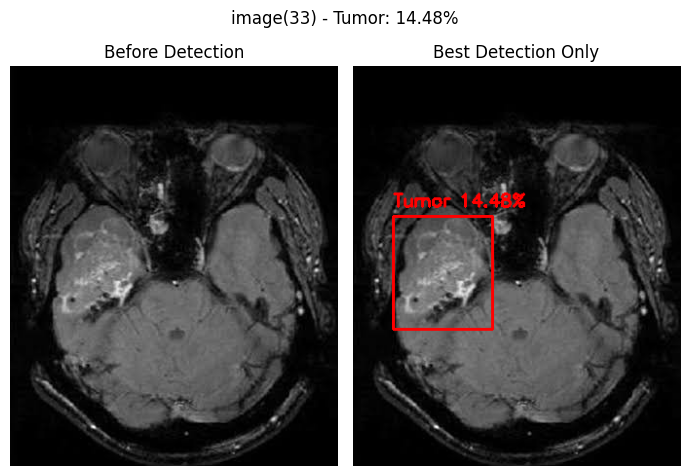


image 1/1 e:\Brain Tumor Detection\image test\image(34).jpg: 640x544 1 Tumor, 156.5ms
Speed: 6.6ms preprocess, 156.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 544)
image(34) -> Tumor: 69.32%


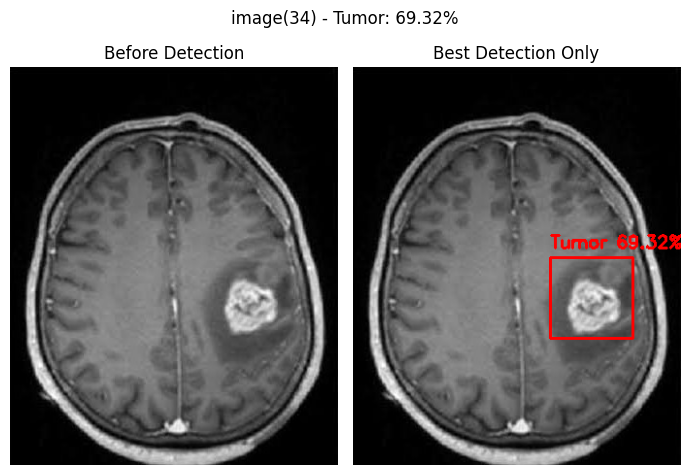


image 1/1 e:\Brain Tumor Detection\image test\image(35).jpg: 640x608 1 Tumor, 194.2ms
Speed: 3.9ms preprocess, 194.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 608)
image(35) -> Tumor: 58.25%


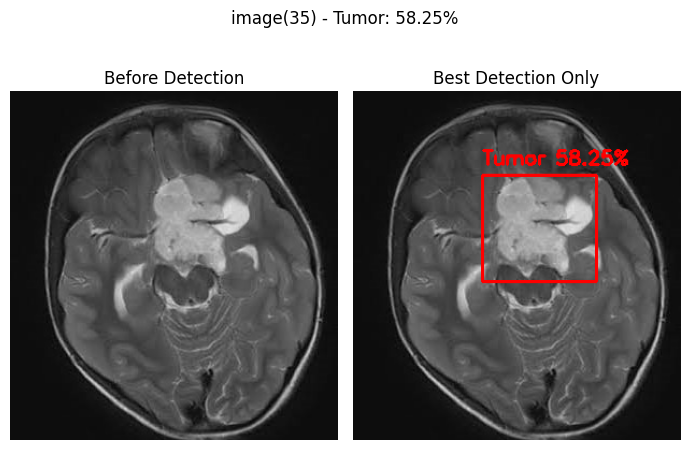


image 1/1 e:\Brain Tumor Detection\image test\image(36).jpg: 608x640 1 Tumor, 202.7ms
Speed: 4.4ms preprocess, 202.7ms inference, 1.7ms postprocess per image at shape (1, 3, 608, 640)
image(36) -> Tumor: 59.55%


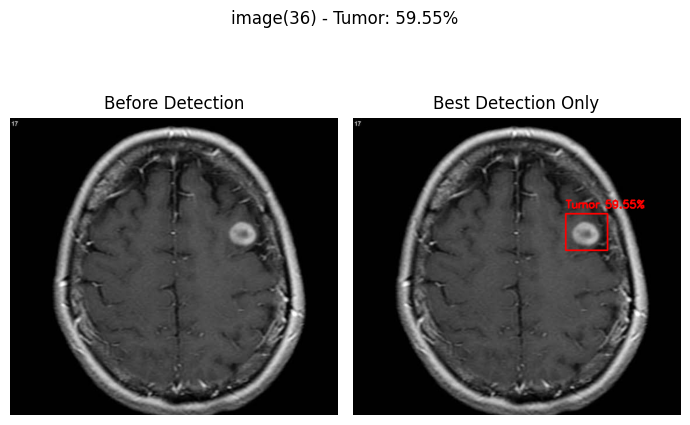


image 1/1 e:\Brain Tumor Detection\image test\image(37).jpg: 608x640 1 Tumor, 192.2ms
Speed: 6.5ms preprocess, 192.2ms inference, 1.7ms postprocess per image at shape (1, 3, 608, 640)
image(37) -> Tumor: 56.27%


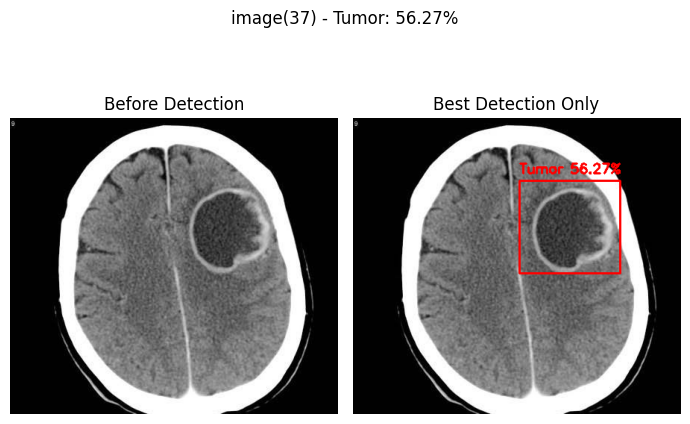


image 1/1 e:\Brain Tumor Detection\image test\image(38).jpg: 640x608 2 Tumors, 196.2ms
Speed: 4.5ms preprocess, 196.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 608)
image(38) -> Tumor: 16.78%


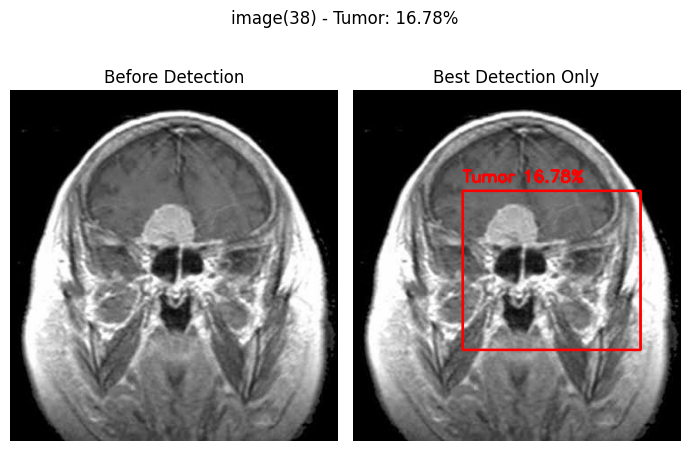


image 1/1 e:\Brain Tumor Detection\image test\image(39).jpg: 640x608 1 Tumor, 192.6ms
Speed: 7.5ms preprocess, 192.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 608)
image(39) -> Tumor: 7.68%


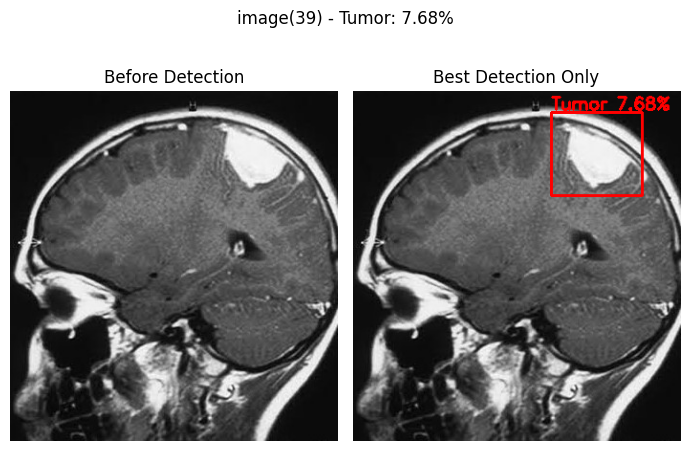


image 1/1 e:\Brain Tumor Detection\image test\image(40).jpg: 640x512 1 Tumor, 169.6ms
Speed: 2.7ms preprocess, 169.6ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 512)
image(40) -> Tumor: 40.05%


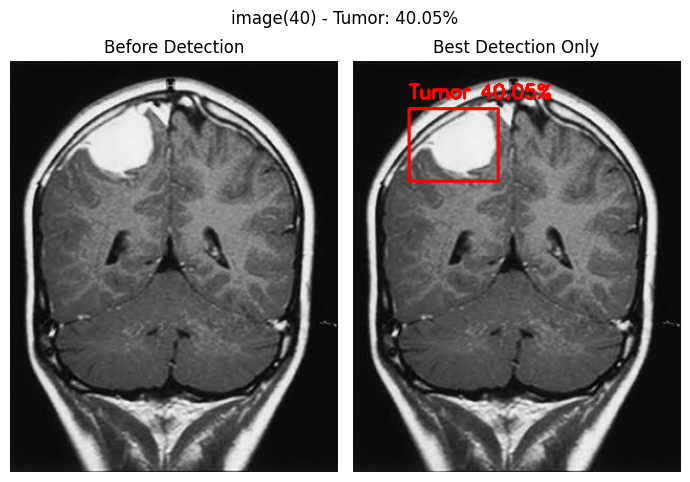


image 1/1 e:\Brain Tumor Detection\image test\image(41).jpg: 640x640 1 Tumor, 220.9ms
Speed: 8.1ms preprocess, 220.9ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
image(41) -> Tumor: 77.63%


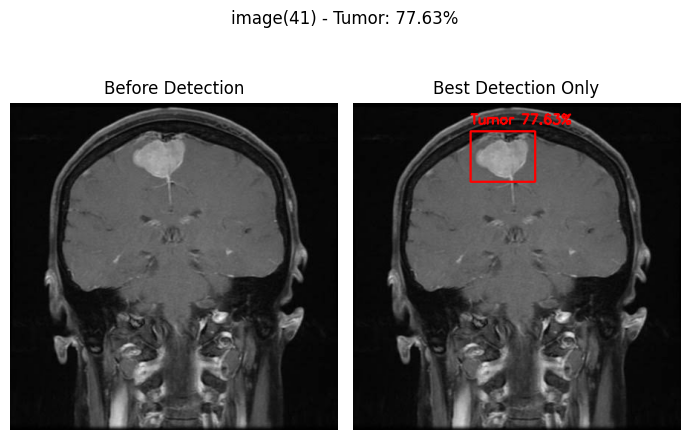


image 1/1 e:\Brain Tumor Detection\image test\image(42).jpg: 640x608 1 Tumor, 330.1ms
Speed: 5.3ms preprocess, 330.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 608)
image(42) -> Tumor: 8.40%


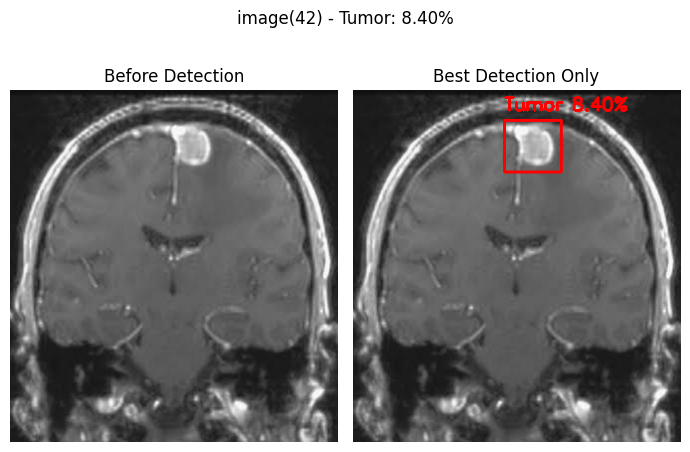


image 1/1 e:\Brain Tumor Detection\image test\image(43).jpg: 640x640 1 Tumor, 191.2ms
Speed: 6.3ms preprocess, 191.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
image(43) -> Tumor: 7.62%


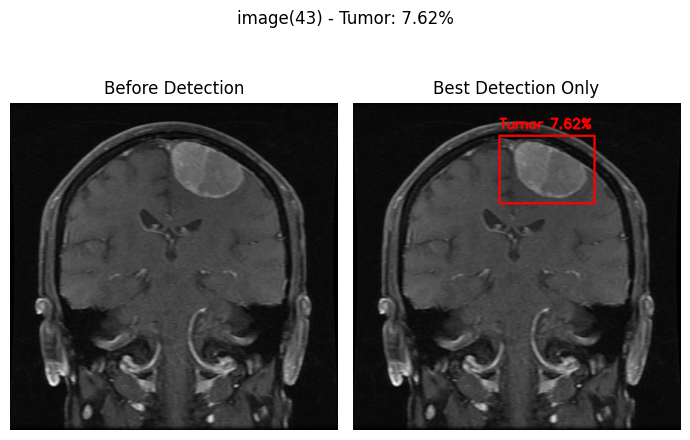


image 1/1 e:\Brain Tumor Detection\image test\image(44).jpg: 640x640 2 Tumors, 216.4ms
Speed: 6.6ms preprocess, 216.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
image(44) -> Tumor: 49.86%


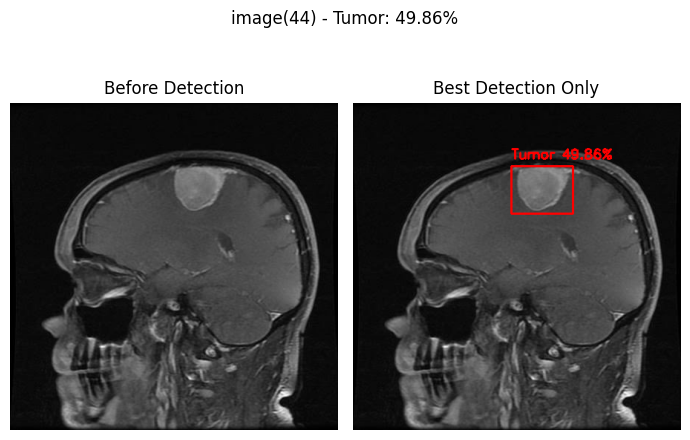


image 1/1 e:\Brain Tumor Detection\image test\image(45).jpg: 640x608 1 Tumor, 307.5ms
Speed: 4.5ms preprocess, 307.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 608)
image(45) -> Tumor: 5.33%


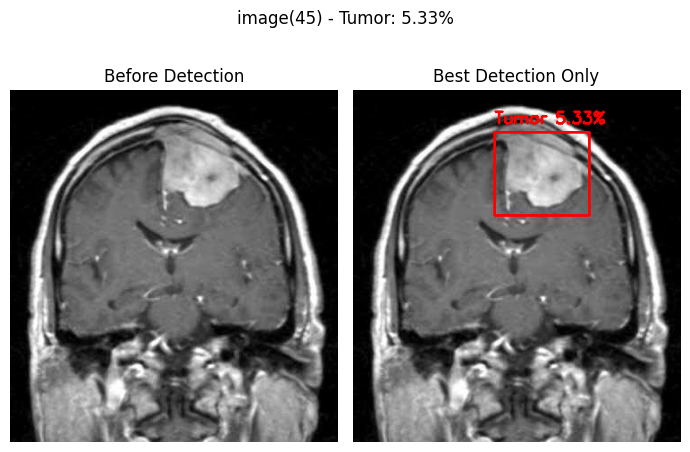


image 1/1 e:\Brain Tumor Detection\image test\image(46).jpg: 640x640 (no detections), 186.3ms
Speed: 4.5ms preprocess, 186.3ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
image(46) -> No Tumor Detected


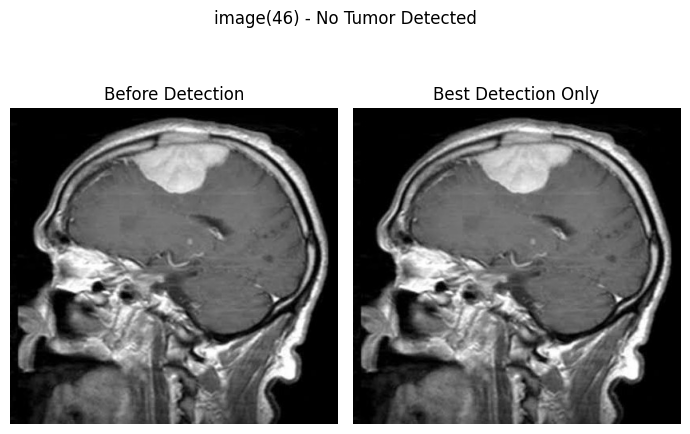


image 1/1 e:\Brain Tumor Detection\image test\image(47).jpg: 608x640 1 Tumor, 196.4ms
Speed: 4.5ms preprocess, 196.4ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 640)
image(47) -> Tumor: 59.69%


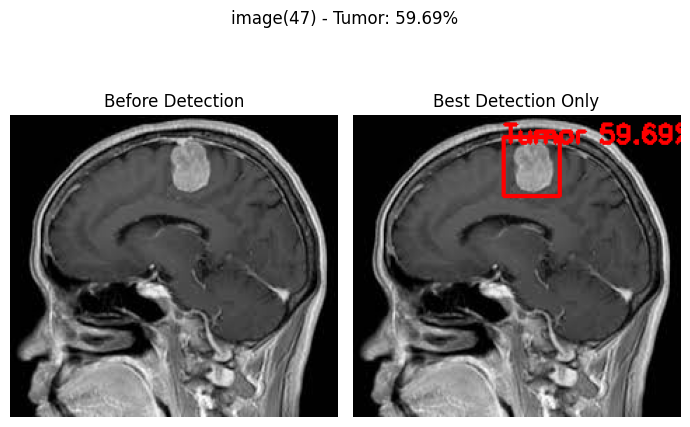


image 1/1 e:\Brain Tumor Detection\image test\image(48).jpg: 640x576 2 Tumors, 172.4ms
Speed: 6.3ms preprocess, 172.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 576)
image(48) -> Tumor: 46.28%


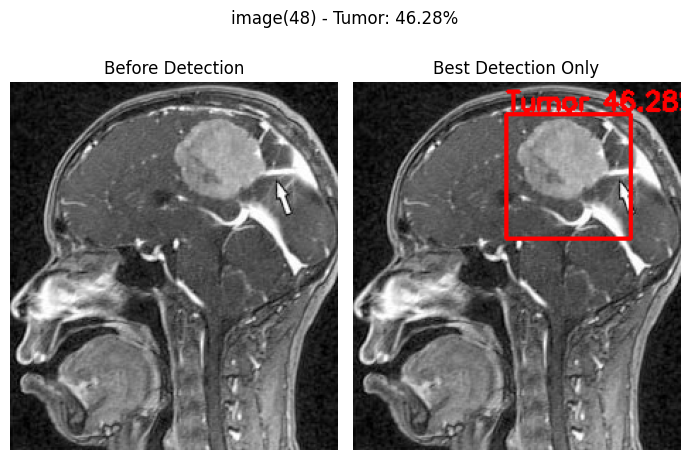


image 1/1 e:\Brain Tumor Detection\image test\image(49).jpg: 448x640 1 Tumor, 137.9ms
Speed: 4.0ms preprocess, 137.9ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)
image(49) -> Tumor: 78.63%


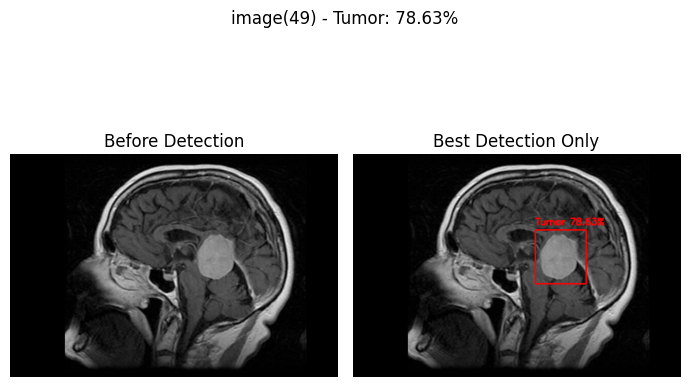


image 1/1 e:\Brain Tumor Detection\image test\image(50).jpg: 640x608 1 Tumor, 204.9ms
Speed: 4.5ms preprocess, 204.9ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 608)
image(50) -> Tumor: 78.59%


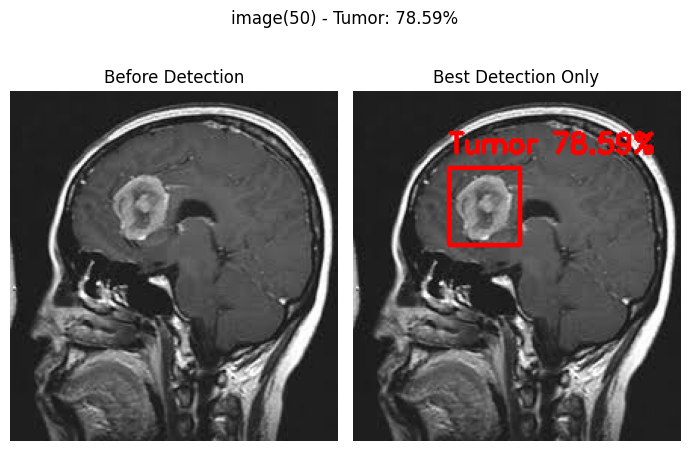


image 1/1 e:\Brain Tumor Detection\image test\image(51).jpg: 608x640 1 Tumor, 183.7ms
Speed: 5.9ms preprocess, 183.7ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 640)
image(51) -> Tumor: 77.11%


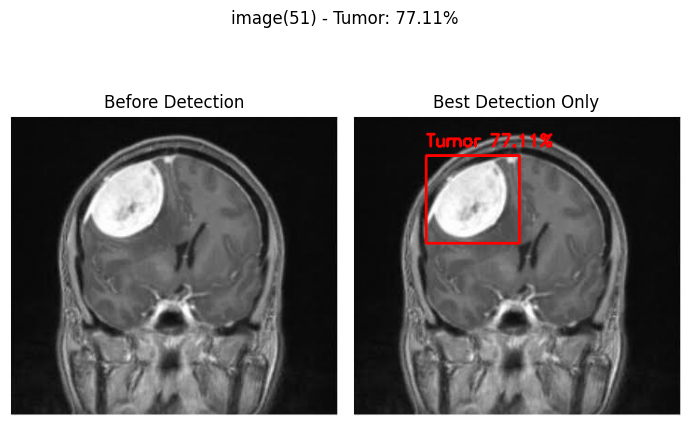


image 1/1 e:\Brain Tumor Detection\image test\image(52).jpg: 640x640 (no detections), 203.2ms
Speed: 8.1ms preprocess, 203.2ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
image(52) -> No Tumor Detected


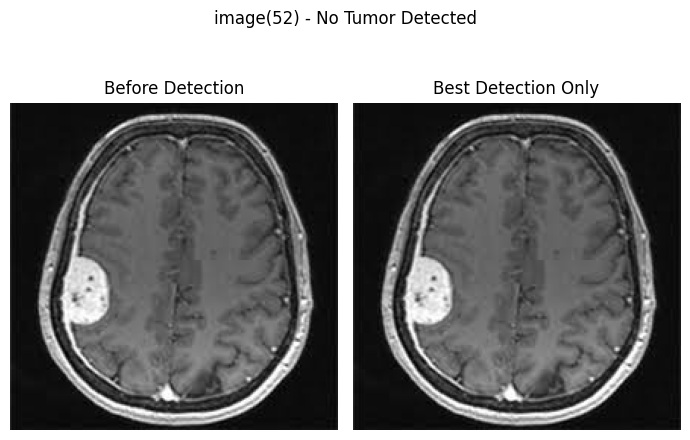


image 1/1 e:\Brain Tumor Detection\image test\image(53).jpg: 640x640 1 Tumor, 215.5ms
Speed: 3.8ms preprocess, 215.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
image(53) -> Tumor: 20.41%


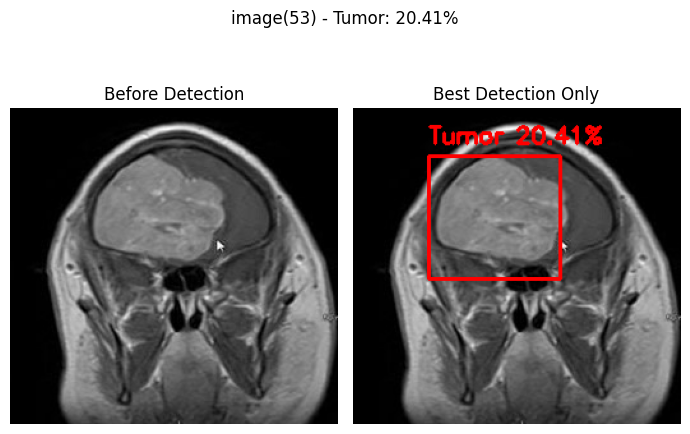


image 1/1 e:\Brain Tumor Detection\image test\image(54).jpg: 640x512 2 Tumors, 172.4ms
Speed: 8.1ms preprocess, 172.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 512)
image(54) -> Tumor: 10.95%


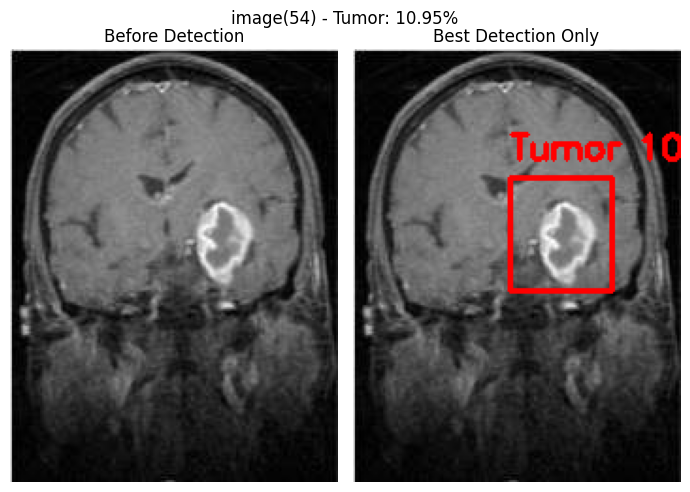


image 1/1 e:\Brain Tumor Detection\image test\image(55).jpg: 640x544 2 Tumors, 209.7ms
Speed: 3.8ms preprocess, 209.7ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 544)
image(55) -> Tumor: 22.51%


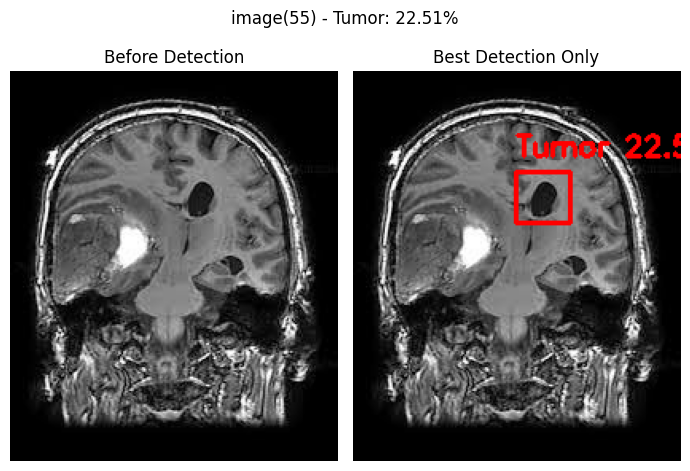


image 1/1 e:\Brain Tumor Detection\image test\image(56).jpg: 576x640 1 Tumor, 285.0ms
Speed: 7.3ms preprocess, 285.0ms inference, 1.7ms postprocess per image at shape (1, 3, 576, 640)
image(56) -> Tumor: 64.92%


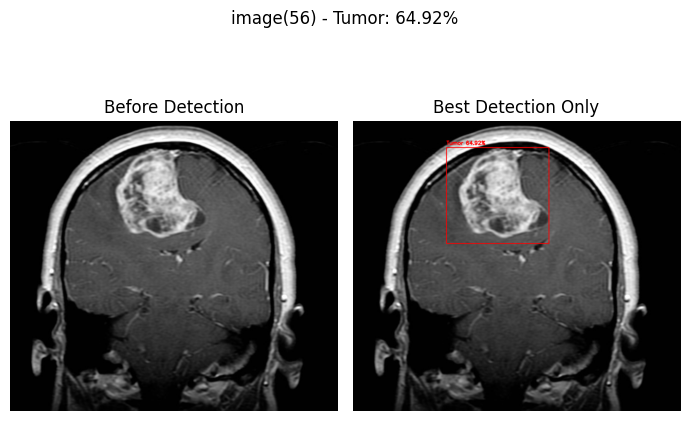


image 1/1 e:\Brain Tumor Detection\image test\image(57).jpg: 640x640 1 Tumor, 225.7ms
Speed: 5.9ms preprocess, 225.7ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
image(57) -> Tumor: 19.08%


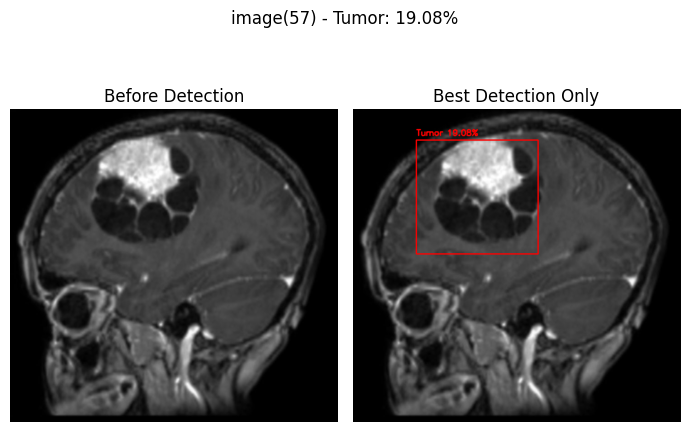


image 1/1 e:\Brain Tumor Detection\image test\image(58).jpg: 640x640 2 Tumors, 223.0ms
Speed: 4.8ms preprocess, 223.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
image(58) -> Tumor: 53.06%


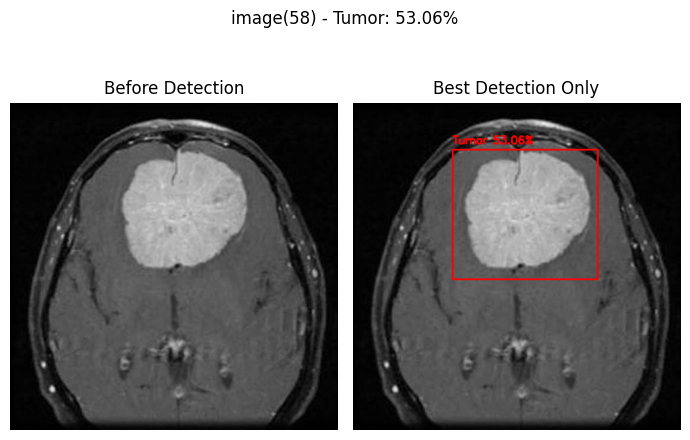


image 1/1 e:\Brain Tumor Detection\image test\image(59).jpg: 640x640 5 Tumors, 200.0ms
Speed: 3.2ms preprocess, 200.0ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
image(59) -> Tumor: 19.15%


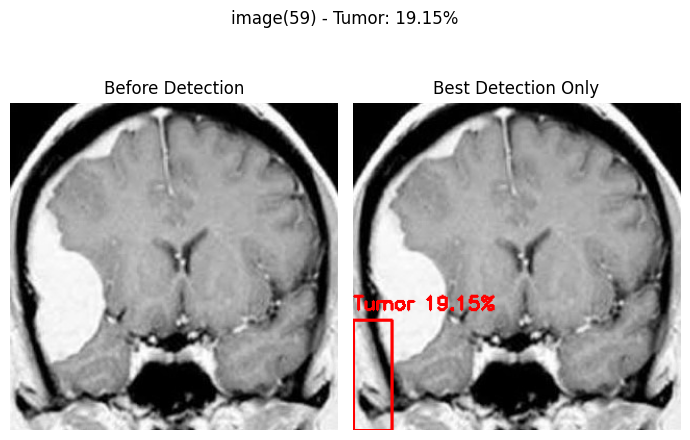


image 1/1 e:\Brain Tumor Detection\image test\image(60).jpg: 640x576 1 Tumor, 190.2ms
Speed: 6.5ms preprocess, 190.2ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 576)
image(60) -> Tumor: 47.20%


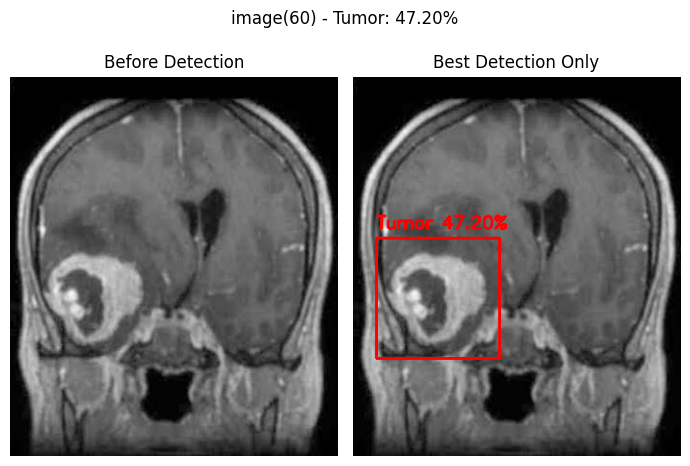


image 1/1 e:\Brain Tumor Detection\image test\image(61).jpg: 640x608 2 Tumors, 422.9ms
Speed: 10.6ms preprocess, 422.9ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 608)
image(61) -> Tumor: 52.83%


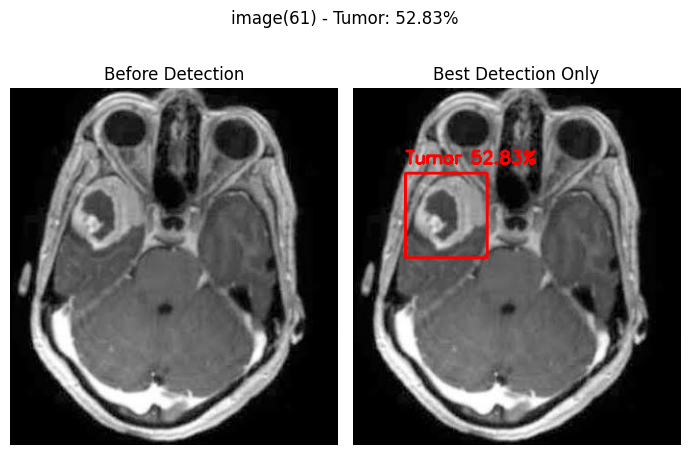


image 1/1 e:\Brain Tumor Detection\image test\image(62).jpg: 640x576 1 Tumor, 556.5ms
Speed: 19.6ms preprocess, 556.5ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 576)
image(62) -> Tumor: 47.20%


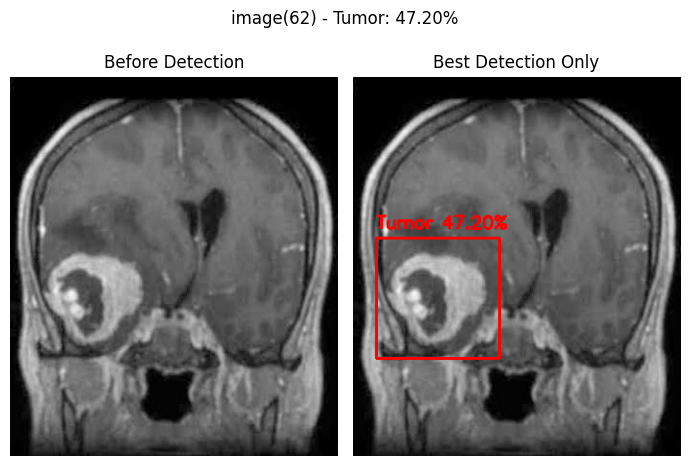


image 1/1 e:\Brain Tumor Detection\image test\image(63).jpg: 640x544 2 Tumors, 363.4ms
Speed: 16.0ms preprocess, 363.4ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 544)
image(63) -> Tumor: 71.60%


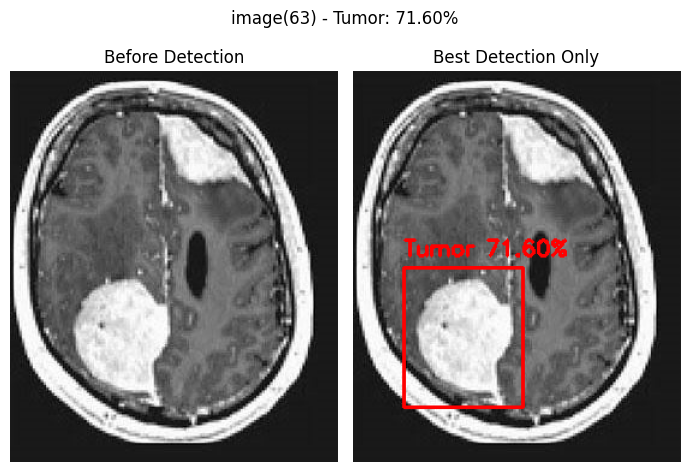


image 1/1 e:\Brain Tumor Detection\image test\image(64).jpg: 640x640 2 Tumors, 860.4ms
Speed: 9.2ms preprocess, 860.4ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 640)
image(64) -> Tumor: 58.45%


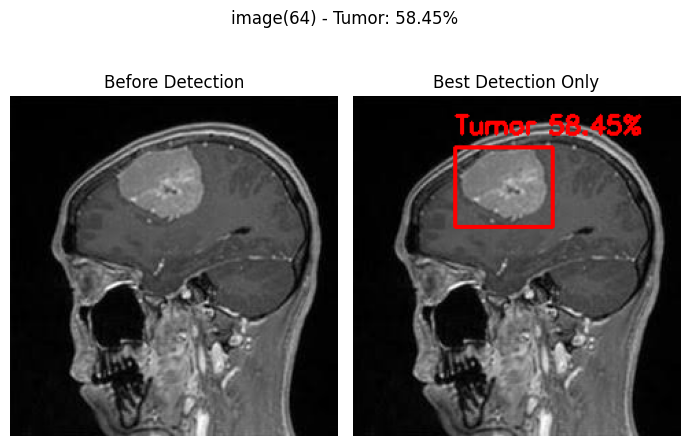


image 1/1 e:\Brain Tumor Detection\image test\image(65).jpg: 640x544 2 Tumors, 1227.6ms
Speed: 12.3ms preprocess, 1227.6ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 544)
image(65) -> Tumor: 71.84%


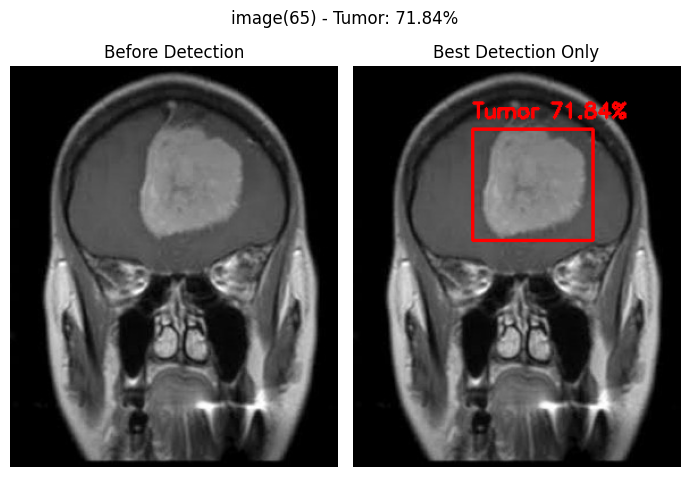


image 1/1 e:\Brain Tumor Detection\image test\image(66).jpg: 640x608 1 Tumor, 521.5ms
Speed: 181.4ms preprocess, 521.5ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 608)
image(66) -> Tumor: 61.79%


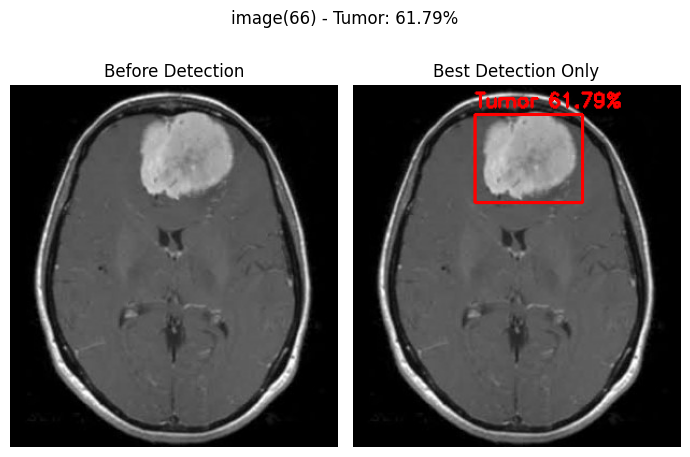


image 1/1 e:\Brain Tumor Detection\image test\image(67).jpg: 640x480 1 Tumor, 465.2ms
Speed: 11.1ms preprocess, 465.2ms inference, 3.6ms postprocess per image at shape (1, 3, 640, 480)
image(67) -> Tumor: 20.10%


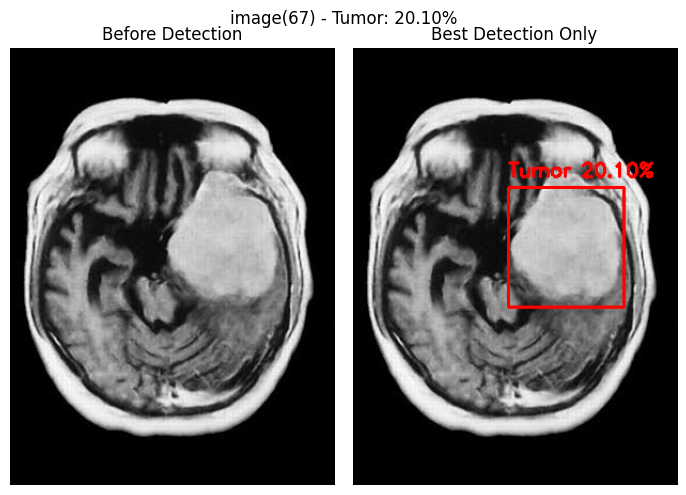


image 1/1 e:\Brain Tumor Detection\image test\image(68).jpg: 640x576 1 Tumor, 441.7ms
Speed: 22.1ms preprocess, 441.7ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 576)
image(68) -> Tumor: 8.70%


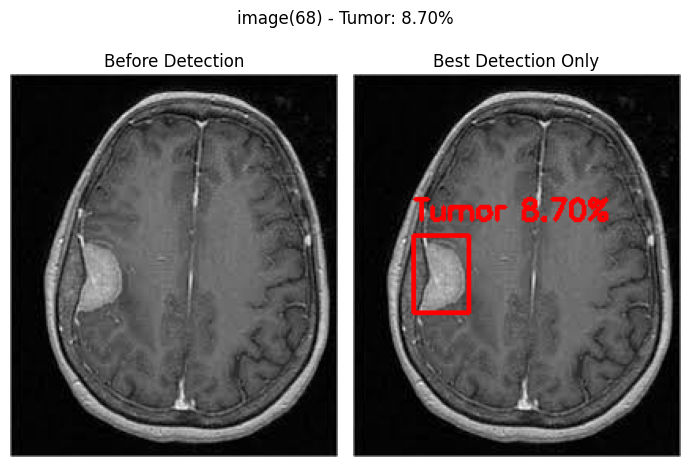


image 1/1 e:\Brain Tumor Detection\image test\image(69).jpg: 640x640 (no detections), 463.4ms
Speed: 27.6ms preprocess, 463.4ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
image(69) -> No Tumor Detected


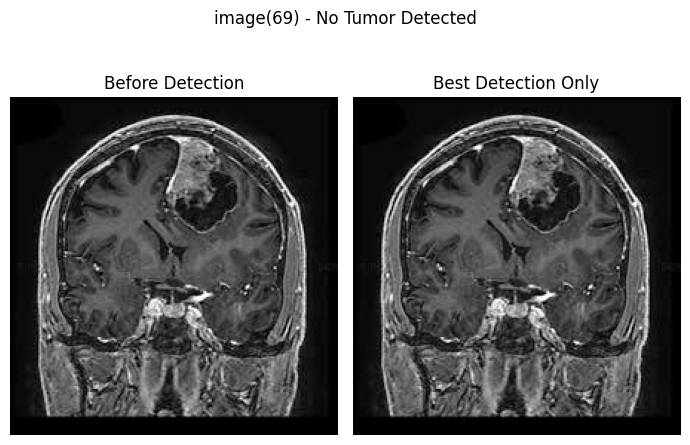


image 1/1 e:\Brain Tumor Detection\image test\image(70).jpg: 640x512 1 Tumor, 403.8ms
Speed: 18.7ms preprocess, 403.8ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 512)
image(70) -> Tumor: 68.95%


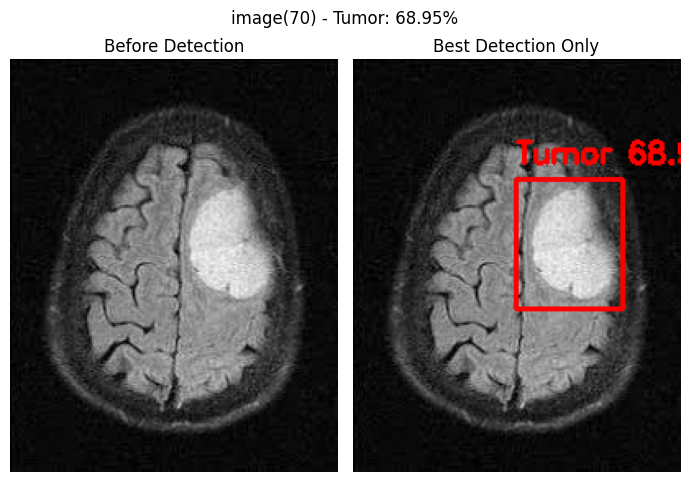


image 1/1 e:\Brain Tumor Detection\image test\image(71).jpg: 608x640 (no detections), 566.9ms
Speed: 15.8ms preprocess, 566.9ms inference, 1.3ms postprocess per image at shape (1, 3, 608, 640)
image(71) -> No Tumor Detected


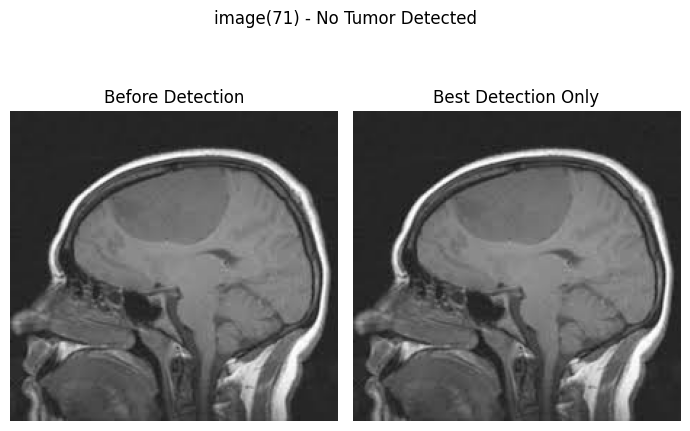


image 1/1 e:\Brain Tumor Detection\image test\image(72).jpg: 640x544 2 Tumors, 405.1ms
Speed: 9.0ms preprocess, 405.1ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 544)
image(72) -> Tumor: 10.64%


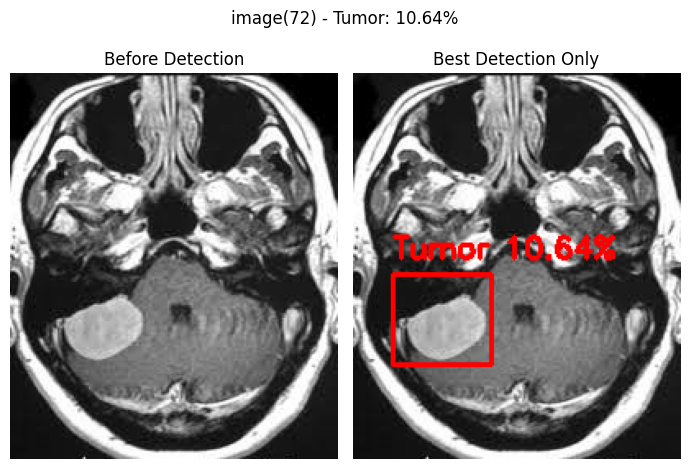


image 1/1 e:\Brain Tumor Detection\image test\image(73).jpg: 576x640 2 Tumors, 404.5ms
Speed: 10.2ms preprocess, 404.5ms inference, 2.3ms postprocess per image at shape (1, 3, 576, 640)
image(73) -> Tumor: 54.74%


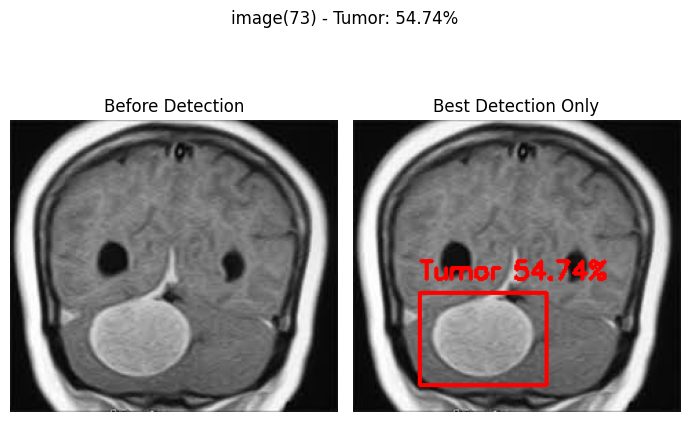


image 1/1 e:\Brain Tumor Detection\image test\image(74).jpg: 640x640 1 Tumor, 460.7ms
Speed: 14.7ms preprocess, 460.7ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)
image(74) -> Tumor: 60.66%


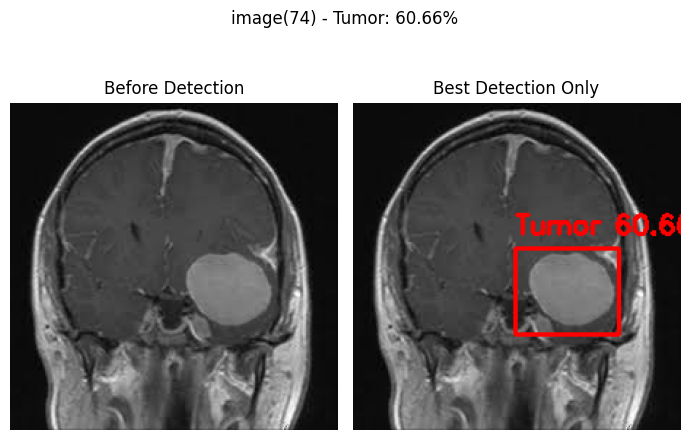


image 1/1 e:\Brain Tumor Detection\image test\image(75).jpg: 640x576 2 Tumors, 515.5ms
Speed: 9.9ms preprocess, 515.5ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 576)
image(75) -> Tumor: 55.25%


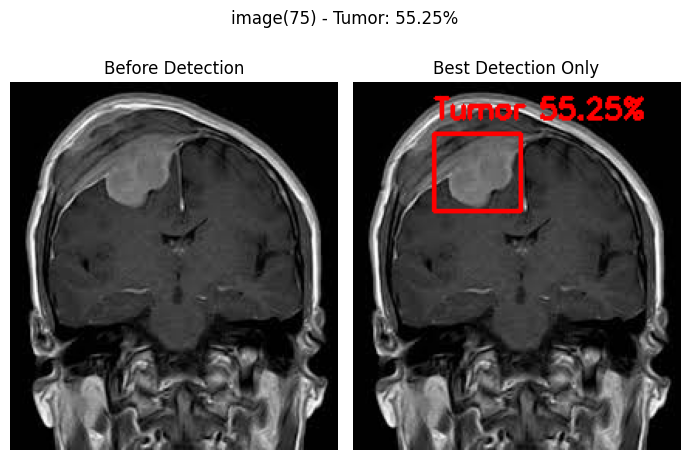


image 1/1 e:\Brain Tumor Detection\image test\image(76).jpg: 640x640 (no detections), 530.3ms
Speed: 38.6ms preprocess, 530.3ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)
image(76) -> No Tumor Detected


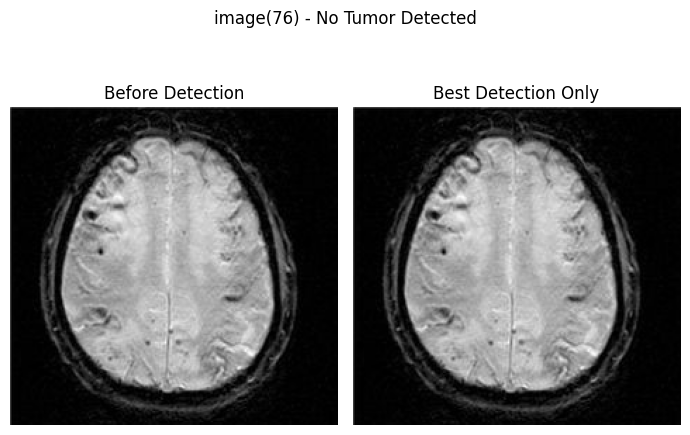


image 1/1 e:\Brain Tumor Detection\image test\image(77).jpg: 640x576 (no detections), 405.3ms
Speed: 13.2ms preprocess, 405.3ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 576)
image(77) -> No Tumor Detected


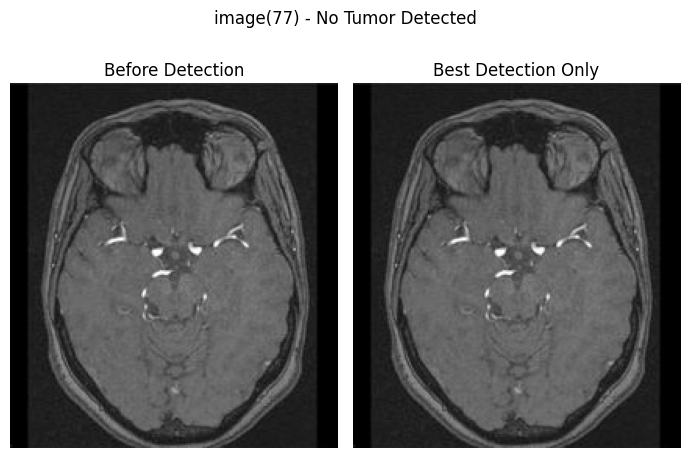


image 1/1 e:\Brain Tumor Detection\image test\image(78).jpg: 640x512 (no detections), 383.9ms
Speed: 10.2ms preprocess, 383.9ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 512)
image(78) -> No Tumor Detected


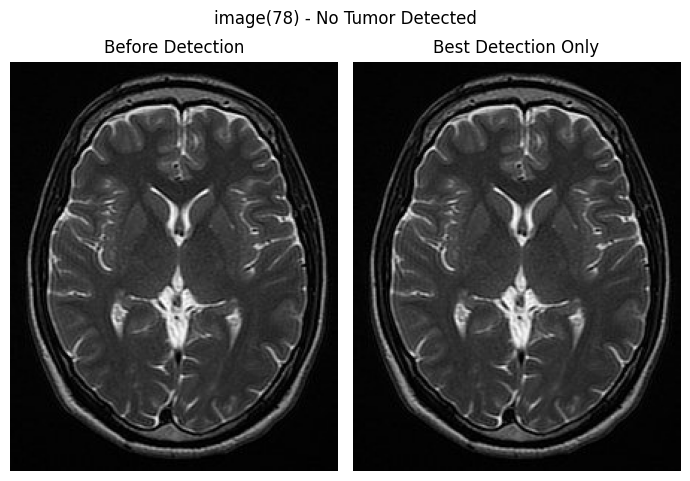


image 1/1 e:\Brain Tumor Detection\image test\image(79).jpg: 640x576 (no detections), 725.4ms
Speed: 80.8ms preprocess, 725.4ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 576)
image(79) -> No Tumor Detected


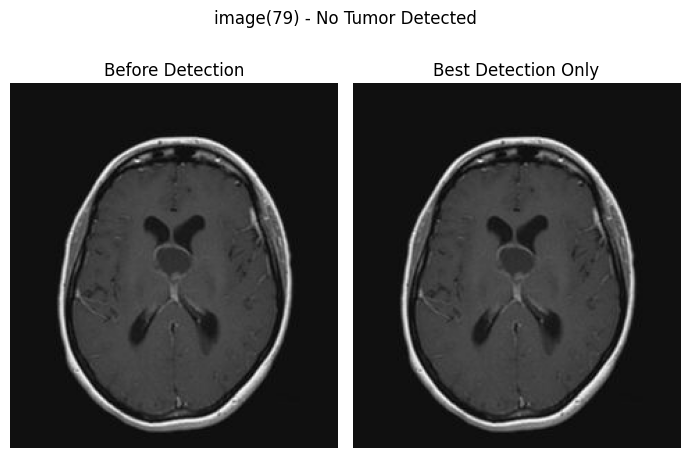


image 1/1 e:\Brain Tumor Detection\image test\image(80).jpg: 640x640 (no detections), 327.0ms
Speed: 9.2ms preprocess, 327.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
image(80) -> No Tumor Detected


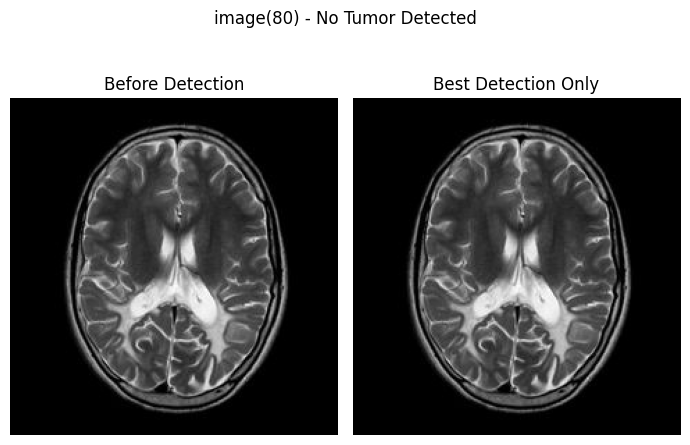


image 1/1 e:\Brain Tumor Detection\image test\image(81).jpg: 640x608 (no detections), 223.1ms
Speed: 5.0ms preprocess, 223.1ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 608)
image(81) -> No Tumor Detected


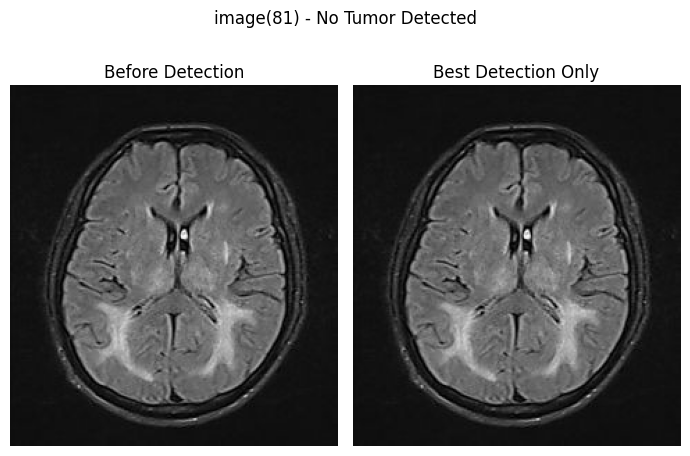


image 1/1 e:\Brain Tumor Detection\image test\image(82).jpg: 640x640 (no detections), 199.3ms
Speed: 4.0ms preprocess, 199.3ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
image(82) -> No Tumor Detected


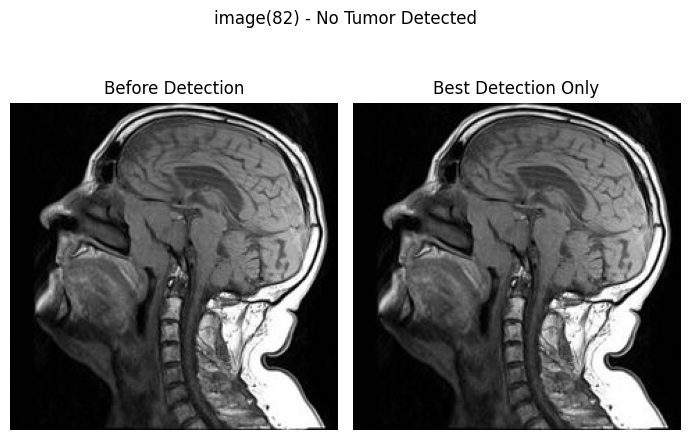


image 1/1 e:\Brain Tumor Detection\image test\image(83).jpg: 640x512 (no detections), 149.4ms
Speed: 3.2ms preprocess, 149.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 512)
image(83) -> No Tumor Detected


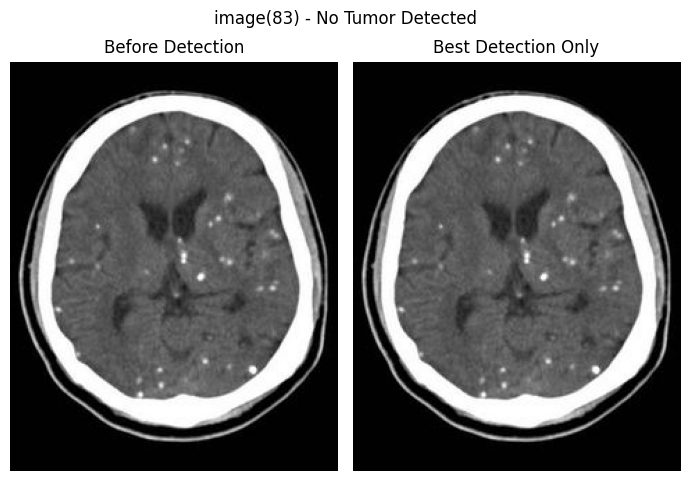


image 1/1 e:\Brain Tumor Detection\image test\image(84).jpg: 640x640 (no detections), 205.8ms
Speed: 3.7ms preprocess, 205.8ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
image(84) -> No Tumor Detected


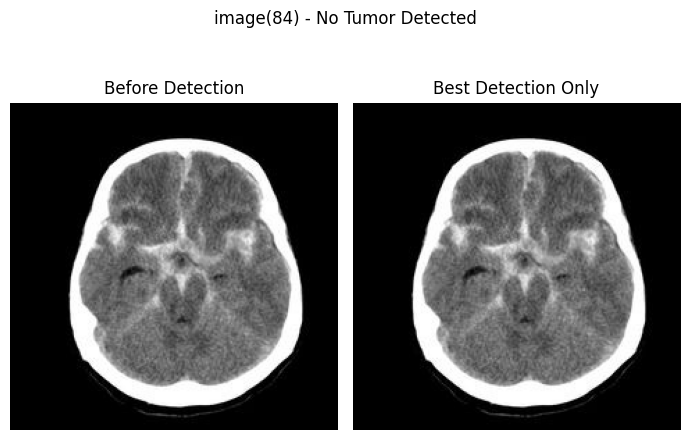


image 1/1 e:\Brain Tumor Detection\image test\image(85).jpg: 640x640 (no detections), 181.0ms
Speed: 4.5ms preprocess, 181.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
image(85) -> No Tumor Detected


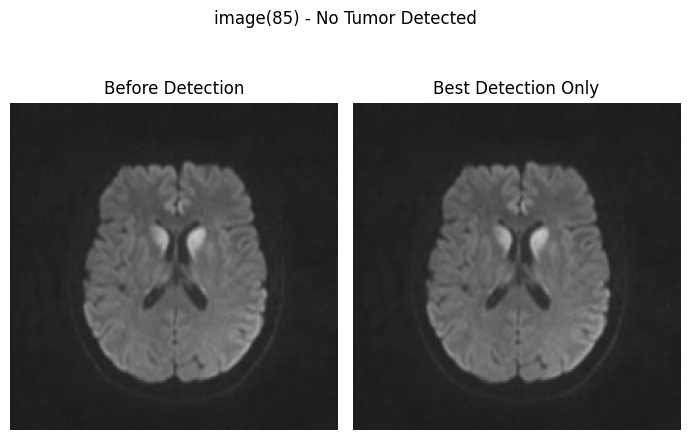


image 1/1 e:\Brain Tumor Detection\image test\image(86).jpg: 640x608 (no detections), 183.0ms
Speed: 6.2ms preprocess, 183.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 608)
image(86) -> No Tumor Detected


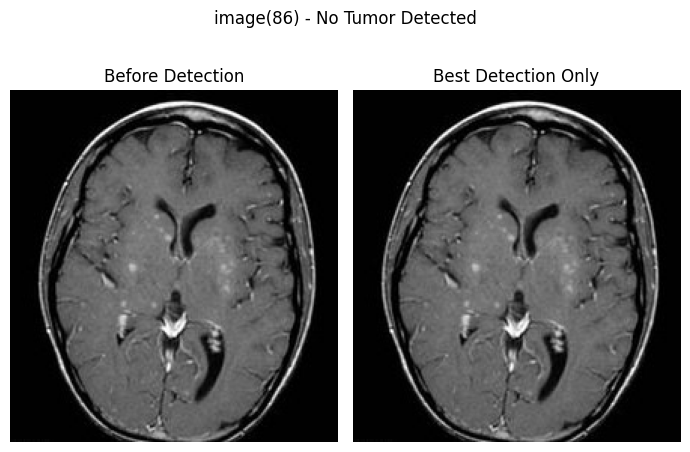


image 1/1 e:\Brain Tumor Detection\image test\image(87).jpg: 640x576 1 Tumor, 183.6ms
Speed: 4.7ms preprocess, 183.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 576)
image(87) -> Tumor: 58.43%


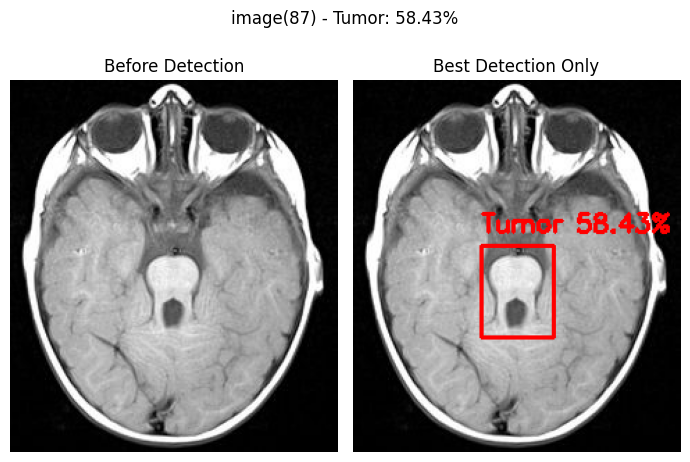


image 1/1 e:\Brain Tumor Detection\image test\image(88).jpg: 640x512 (no detections), 196.0ms
Speed: 6.0ms preprocess, 196.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 512)
image(88) -> No Tumor Detected


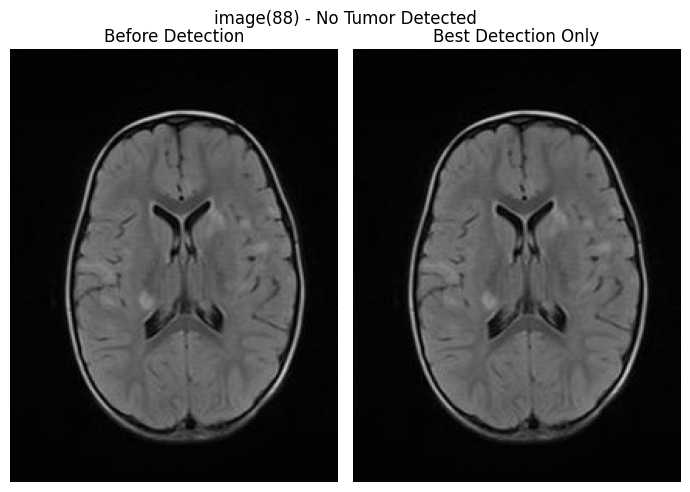


image 1/1 e:\Brain Tumor Detection\image test\image(89).jpg: 640x512 1 Tumor, 171.0ms
Speed: 3.4ms preprocess, 171.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 512)
image(89) -> Tumor: 7.99%


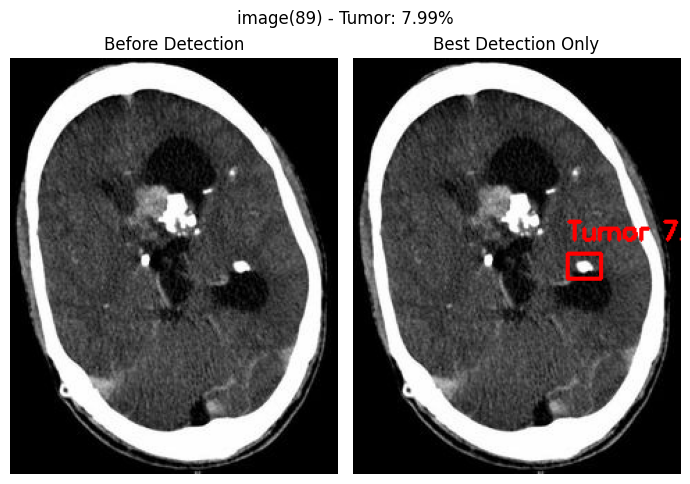


image 1/1 e:\Brain Tumor Detection\image test\image(90).jpg: 640x480 (no detections), 158.7ms
Speed: 2.7ms preprocess, 158.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 480)
image(90) -> No Tumor Detected


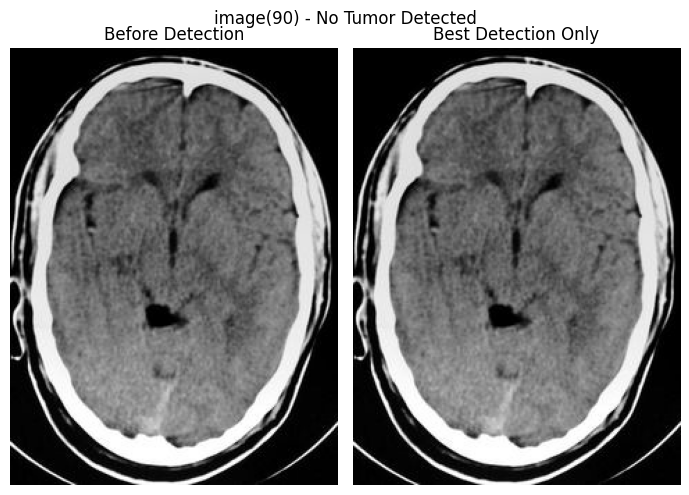


image 1/1 e:\Brain Tumor Detection\image test\image(91).jpg: 640x608 (no detections), 187.5ms
Speed: 3.1ms preprocess, 187.5ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 608)
image(91) -> No Tumor Detected


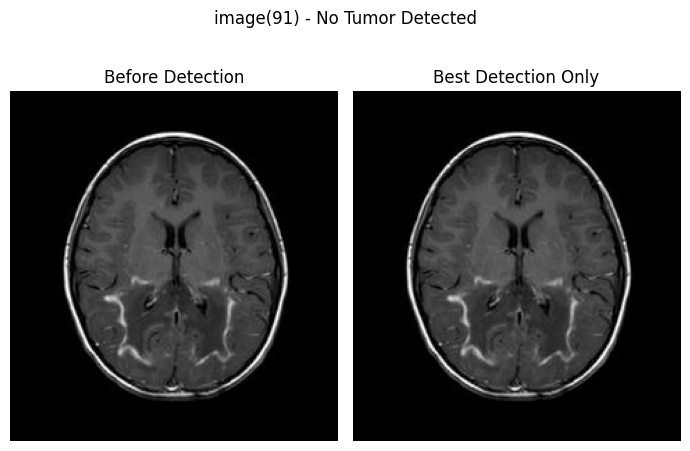


image 1/1 e:\Brain Tumor Detection\image test\image(92).jpg: 640x640 (no detections), 186.3ms
Speed: 3.5ms preprocess, 186.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
image(92) -> No Tumor Detected


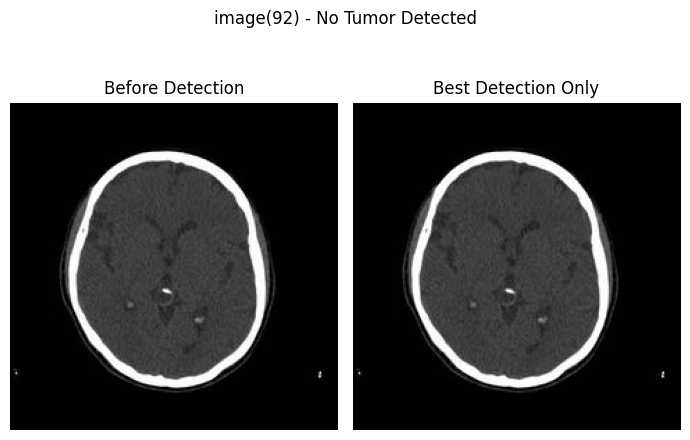


image 1/1 e:\Brain Tumor Detection\image test\image(93).jpg: 640x640 (no detections), 183.3ms
Speed: 4.9ms preprocess, 183.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
image(93) -> No Tumor Detected


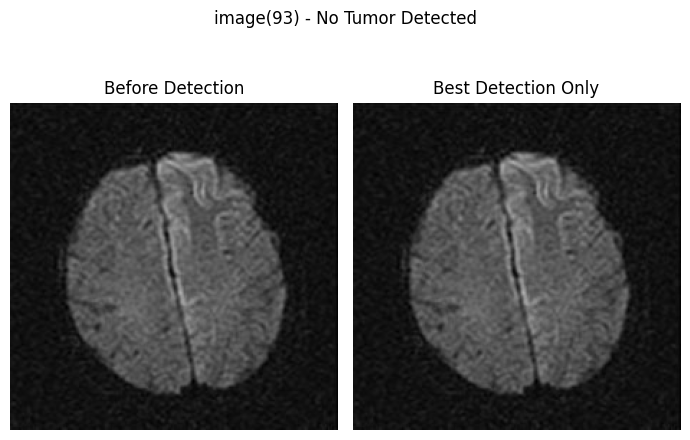


image 1/1 e:\Brain Tumor Detection\image test\image(94).jpg: 640x640 1 Tumor, 305.8ms
Speed: 3.8ms preprocess, 305.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
image(94) -> Tumor: 42.03%


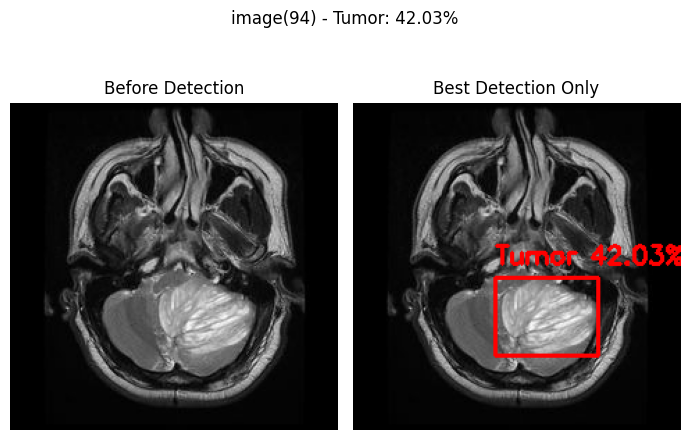


image 1/1 e:\Brain Tumor Detection\image test\image(95).jpg: 576x640 (no detections), 173.5ms
Speed: 3.2ms preprocess, 173.5ms inference, 0.7ms postprocess per image at shape (1, 3, 576, 640)
image(95) -> No Tumor Detected


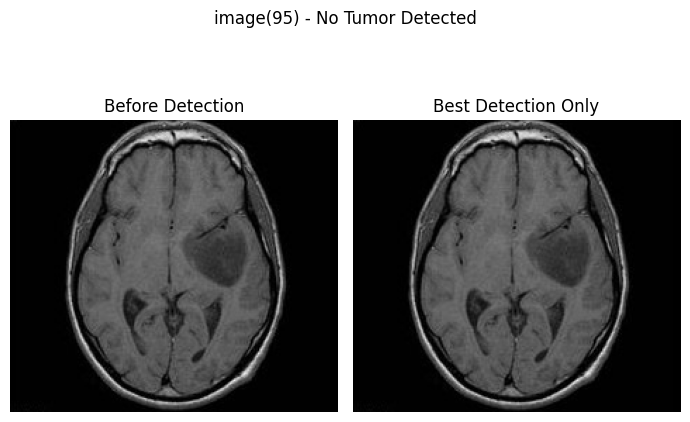


image 1/1 e:\Brain Tumor Detection\image test\image(96).jpg: 640x576 (no detections), 417.9ms
Speed: 4.8ms preprocess, 417.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 576)
image(96) -> No Tumor Detected


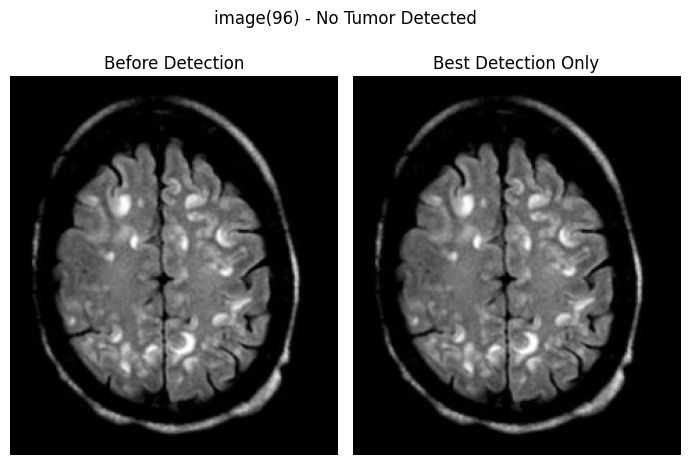


image 1/1 e:\Brain Tumor Detection\image test\image(97).jpg: 640x608 (no detections), 328.4ms
Speed: 11.1ms preprocess, 328.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 608)
image(97) -> No Tumor Detected


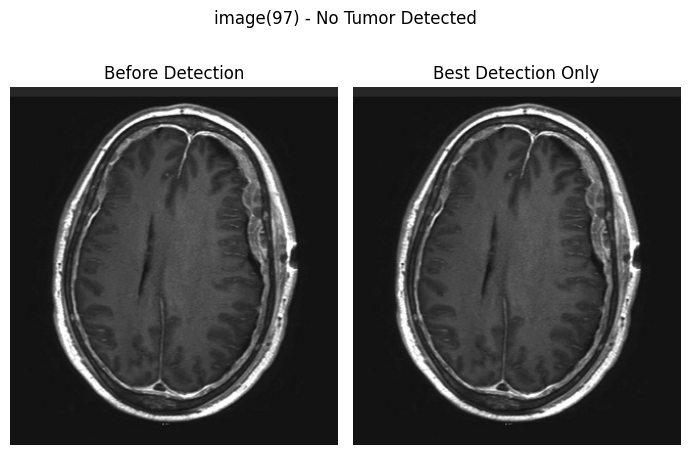


image 1/1 e:\Brain Tumor Detection\image test\image(98).jpg: 640x576 (no detections), 193.3ms
Speed: 4.8ms preprocess, 193.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 576)
image(98) -> No Tumor Detected


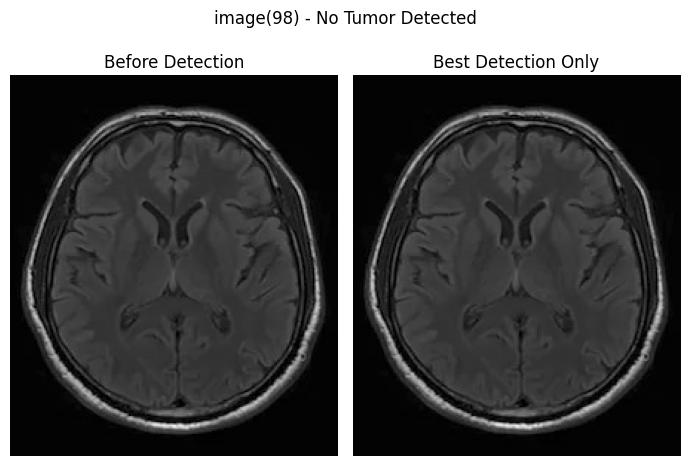


image 1/1 e:\Brain Tumor Detection\image test\image(99).jpg: 640x576 (no detections), 278.2ms
Speed: 3.0ms preprocess, 278.2ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 576)
image(99) -> No Tumor Detected


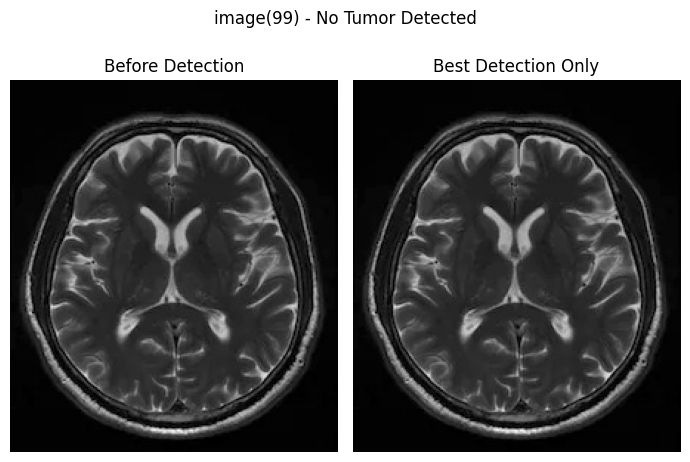

FINAL RESULTS
Total Images: 98
Tumor Detected: 70
No Tumor Detected: 28
No Image Path: 0
Highest Confidence: 85.82%
Highest Confidence Image: image test\image(4).jpg

image 1/1 e:\Brain Tumor Detection\image test\image(4).jpg: 544x640 3 Tumors, 169.6ms
Speed: 4.3ms preprocess, 169.6ms inference, 1.5ms postprocess per image at shape (1, 3, 544, 640)


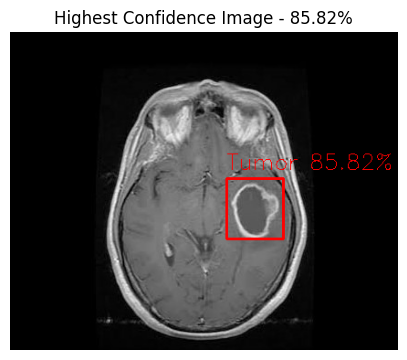

Ultralytics 8.4.150  Python-3.11.9 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-1185G7 @ 3.00GHz)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.20.2 ms, read: 2.30.9 MB/s, size: 17.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\Brain Tumor Detection\dataset\YOLO_Dataset\labels\val... 119 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 450.9it/s 0.3s2s
val: New cache created: E:\Brain Tumor Detection\dataset\YOLO_Dataset\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0s/it 24.0s3.3ss
                   all        119         76      0.869       0.87      0.885      0.553
Speed: 2.3ms preprocess, 188.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to E:\Brain Tumor Detection\ru

In [7]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
show = True
conf_me = 0.05
img_tst_count = 100
yes_list, no_list, noimg = [], [], 0
highest_confidence = 0
highest_image = ""
for i in range(2, img_tst_count):
    image_path = f"image test\image({i}).jpg"
    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        noimg += 1
        continue
    results = model.predict(source=image_path, conf=conf_me, save=False, show=False)
    result = results[0]
    original_img = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)
    if len(result.boxes) == 0:
        status = "No Tumor Detected"
        no_list.append(image_path)
        annotated_img = original_img.copy()
    else:
        yes_list.append(image_path)
        confidences = result.boxes.conf.cpu().numpy()
        best_index = confidences.argmax()
        best_confidence = confidences[best_index]
        best_box = result.boxes.xyxy[best_index].cpu().numpy()
        x1, y1, x2, y2 = map(int, best_box)
        annotated_img = original_img.copy()
        cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"Tumor {best_confidence * 100:.2f}%"
        cv2.putText(
            annotated_img,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2,
        )
        status = f"Tumor: {best_confidence * 100:.2f}%"
        if best_confidence > highest_confidence:
            highest_confidence = best_confidence
            highest_image = image_path
    print(f"image({i}) -> {status}")
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(7, 5))
        axes[0].imshow(original_img)
        axes[0].set_title("Before Detection")
        axes[0].axis("off")
        axes[1].imshow(annotated_img)
        axes[1].set_title("Best Detection Only")
        axes[1].axis("off")
        plt.suptitle(f"image({i}) - {status}")
        plt.tight_layout()
        plt.show()


### Info from the all images
total_images = len(yes_list) + len(no_list)
print("=" * 40)
print("FINAL RESULTS")
print("=" * 40)
print(f"Total Images: {total_images}")
print(f"Tumor Detected: {len(yes_list)}")
print(f"No Tumor Detected: {len(no_list)}")
print(f"No Image Path: {noimg}")
if highest_confidence > 0:
    print(f"Highest Confidence: " f"{highest_confidence * 100:.2f}%")
    print(f"Highest Confidence Image: {highest_image}")
else:
    print("Highest Confidence: 0.00%")
print("=" * 40)
img = cv2.imread(highest_image)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
results = model.predict(source=highest_image, conf=0.1, save=False, show=False)
result = results[0]
if len(result.boxes) > 0:
    confidences = result.boxes.conf.cpu().numpy()
    best_index = confidences.argmax()
    box = result.boxes.xyxy[best_index].cpu().numpy()
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    confidence = confidences[best_index]
    cv2.putText(
        img,
        f"Tumor {confidence * 100:.2f}%",
        (x1, max(y1 - 10, 30)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 0),
        1,
    )
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Highest Confidence Image - " f"{confidence * 100:.2f}%")
    plt.axis("off")
    plt.show()


from ultralytics import YOLO

model = YOLO(r"runs\detect\BrainTumor\YOLOv8s\weights\best.pt")
results = model.val(
    data=r"dataset\YOLO_Dataset\data.yaml", imgsz=640, conf=0.02, verbose=True
)
print("\n===== RESULTS =====")
pr = results.box.mp
recall = results.box.mr
map501 = results.box.map50
map5095 = results.box.map
print("Precision:", pr)
print("Recall:", recall)
print("mAP50:", map501)
print("mAP50-95:", map5095)

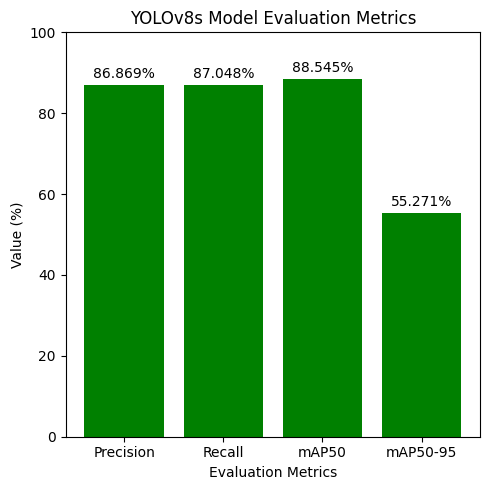

In [9]:
import matplotlib.pyplot as plt

metrics = ["Precision", "Recall", "mAP50", "mAP50-95"]
values = [pr, recall, map501, map5095]
values_percent = [v * 100 for v in values]
plt.figure(figsize=(5, 5))
bars = plt.bar(metrics, values_percent, color="g")
plt.title("YOLOv8s Model Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Value (%)")
plt.ylim(0, 100)
for bar, value in zip(bars, values_percent):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.3f}%",
        ha="center",
        va="bottom",
    )
plt.tight_layout()
plt.show()